# Milestone 2 - Object Detection with YOLOv8

Pipeline: final Milestone 1 single-object photos → audit → source-level 70/15/15 split → grid composites (2x2 / 3x3 / variable) → automatic YOLO labels → validation → YOLOv8s fine-tuning → test evaluation → demo detections.

Run on Google Colab with a T4 GPU (`Runtime → Change runtime type → T4 GPU`), then `Runtime → Run all`.

## 1. Configuration

No paths need editing: Google Drive is mounted and the Milestone 1 / Milestone 2 folders are found automatically in section 2.

In [5]:
SEED = 42

# Number of generated multi-object images (group minimum is 4 students x 100 = 400)
TRAIN_COMPOSITES = 1000
VAL_COMPOSITES = 200
TEST_COMPOSITES = 200

LAYOUT_2X2_RATIO = 0.50
LAYOUT_3X3_RATIO = 0.30
LAYOUT_VARIABLE_RATIO = 0.20

IMAGE_SIZE = 640

MODEL_NAME = "yolov8s.pt"
EPOCHS = 50
BATCH_SIZE = 16
PATIENCE = 10

FORCE_REGENERATE = False   # True = rebuild the composites even if a matching valid dataset exists
FORCE_RETRAIN = False      # True = train again even if a finished best.pt for this configuration exists

RUN_SMOKE_TEST = True      # 1-epoch check on 10% of train before a fresh full run
CONF_THRESHOLD = 0.25      # confidence for demo detections and error analysis
IOU_MATCH_THRESHOLD = 0.5  # IoU for matching a detection to a ground-truth box

# Derived settings (not meant to be edited)
NUM_CLASSES = 73
SOURCE_SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
LAYOUT_MIX = {"2x2": LAYOUT_2X2_RATIO, "3x3": LAYOUT_3X3_RATIO, "variable": LAYOUT_VARIABLE_RATIO}
assert abs(sum(LAYOUT_MIX.values()) - 1.0) < 1e-9, "layout ratios must add up to 1"
VARIABLE_GRIDS = [(1, 2), (1, 3), (2, 2), (2, 3), (3, 2), (3, 3)]   # (rows, cols)
CANVAS_SIZE = IMAGE_SIZE

TRAIN_RUN_NAME = "yolov8s_milestone2"
TRAIN_CONFIG = dict(
    model=MODEL_NAME,
    imgsz=IMAGE_SIZE,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    device=0,
    patience=PATIENCE,
    seed=SEED,
    pretrained=True,
    workers=2,          # Colab gives 2 CPU cores
    cache=True,
    save=True,
    deterministic=True,
    # Conservative augmentation: the composites already vary layout, so no mosaic/mixup
    mosaic=0.0,
    close_mosaic=0,
    mixup=0.0,
    copy_paste=0.0,
    degrees=0.0,
    translate=0.05,
    scale=0.2,
    fliplr=0.5,
    hsv_h=0.01,
    hsv_s=0.4,
    hsv_v=0.3,
)

## 2. Google Drive Setup

Expected layout (folder names like `Milestone 1` / `Milestone1` are also accepted):

```
MyDrive/DL/milestone1/dataset_ready/images_OBJ001 ... images_OBJ073
MyDrive/DL/milestone1/outputs/master_dataset.csv, class_mapping.csv
MyDrive/DL/milestone2/milestone2_yolov8.ipynb
```

In [6]:
import csv
import re
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/DL")
else:
    # Local run: the notebook folder sits next to the Milestone 1 folder
    DRIVE_ROOT = Path.cwd().parent

if not DRIVE_ROOT.is_dir():
    raise FileNotFoundError(f"{DRIVE_ROOT} does not exist. Create MyDrive/DL/ and put milestone1/ and milestone2/ inside it.")


def find_milestone_folder(parent, number):
    # Accepts milestone1, Milestone 1, Milestone1, milestone_1 ...; prefers the lowercase canonical name
    canonical = f"milestone{number}"
    matches = sorted(p for p in parent.iterdir()
                     if p.is_dir() and re.sub(r"[\s_\-]", "", p.name.lower()) == canonical)
    if not matches:
        raise FileNotFoundError(f"Missing folder: {parent / canonical}")
    for p in matches:
        if p.name == canonical:
            return p
    if len(matches) > 1:
        raise FileNotFoundError(f"Several Milestone {number} folders found, rename one to '{canonical}': {[p.name for p in matches]}")
    return matches[0]


def find_finalized_csv(outputs_dir, preferred_name, required_columns):
    # Use the preferred file; otherwise accept exactly one other CSV in outputs/ with the identical column set
    preferred = outputs_dir / preferred_name
    if preferred.is_file():
        return preferred
    candidates = []
    for f in sorted(outputs_dir.glob("*.csv")):
        with open(f, newline="", encoding="utf-8") as handle:
            header = next(csv.reader(handle), [])
        if set(h.strip() for h in header) == set(required_columns):
            candidates.append(f)
    if len(candidates) == 1:
        print(f"NOTE: {preferred_name} not found, using {candidates[0].name} (same columns)")
        return candidates[0]
    raise FileNotFoundError(f"Missing {preferred} (columns {required_columns}); "
                            f"matching alternatives in outputs/: {[c.name for c in candidates] or 'none'}")


MILESTONE1_ROOT = find_milestone_folder(DRIVE_ROOT, 1)
PROJECT_ROOT = find_milestone_folder(DRIVE_ROOT, 2)
SOURCE_DATA_ROOT = MILESTONE1_ROOT / "dataset_ready"
MILESTONE1_OUTPUTS = MILESTONE1_ROOT / "outputs"
if not SOURCE_DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Missing folder: {SOURCE_DATA_ROOT} (copy Milestone 1 dataset_ready/ here)")
if not MILESTONE1_OUTPUTS.is_dir():
    raise FileNotFoundError(f"Missing folder: {MILESTONE1_OUTPUTS} (copy Milestone 1 outputs/ here)")
MASTER_DATASET_FILE = find_finalized_csv(MILESTONE1_OUTPUTS, "master_dataset.csv",
                                         ["filepath", "source_object_id", "model_label", "is_background", "sha256"])
CLASS_MAPPING_FILE = find_finalized_csv(MILESTONE1_OUTPUTS, "class_mapping.csv", ["class_index", "object_id", "object_name"])

ARTIFACTS_ROOT = PROJECT_ROOT / "artifacts"
YOLO_DATASET_DIR = ARTIFACTS_ROOT / "yolo_dataset"
RUNS_DIR = ARTIFACTS_ROOT / "runs"
DEMO_DIR = ARTIFACTS_ROOT / "demo_results"
RESULTS_DIR = ARTIFACTS_ROOT / "results"
MODELS_DIR = ARTIFACTS_ROOT / "models"
LOCAL_TRAIN_DATASET_DIR = Path("/content/yolo_dataset")   # Colab local SSD copy used for training
BEST_WEIGHTS = RUNS_DIR / TRAIN_RUN_NAME / "weights" / "best.pt"
for folder in [ARTIFACTS_ROOT, RUNS_DIR, DEMO_DIR, RESULTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Milestone 1 root:", MILESTONE1_ROOT)
print("Dataset root    :", SOURCE_DATA_ROOT)
print("Master dataset  :", MASTER_DATASET_FILE)
print("Class mapping   :", CLASS_MAPPING_FILE)
print("Milestone 2 root:", PROJECT_ROOT)
print("Artifacts root  :", ARTIFACTS_ROOT)

print("\nGOOGLE DRIVE SETUP\n")
for label, path in [("Milestone 1", MILESTONE1_ROOT), ("Milestone 2", PROJECT_ROOT), ("dataset_ready", SOURCE_DATA_ROOT),
                    ("master_dataset.csv", MASTER_DATASET_FILE), ("class_mapping.csv", CLASS_MAPPING_FILE)]:
    print(f"{label}: {'FOUND' if path.exists() else 'MISSING'}")
print("\nDRIVE PATH CHECK: PASS")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Milestone 1 root: /content/drive/MyDrive/DL/Milestone 1
Dataset root    : /content/drive/MyDrive/DL/Milestone 1/dataset_ready
Master dataset  : /content/drive/MyDrive/DL/Milestone 1/outputs/master_dataset.csv
Class mapping   : /content/drive/MyDrive/DL/Milestone 1/outputs/class_mapping.csv
Milestone 2 root: /content/drive/MyDrive/DL/Milestone 2
Artifacts root  : /content/drive/MyDrive/DL/Milestone 2/artifacts

GOOGLE DRIVE SETUP

Milestone 1: FOUND
Milestone 2: FOUND
dataset_ready: FOUND
master_dataset.csv: FOUND
class_mapping.csv: FOUND

DRIVE PATH CHECK: PASS


## 3. Environment Setup

In [7]:
import subprocess

try:
    import ultralytics
except ImportError:
    if IN_COLAB:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)

import hashlib
import json
import platform
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageFont

try:
    import torch
    import ultralytics
    from ultralytics import YOLO
    ULTRALYTICS_AVAILABLE = True
except ImportError:
    ULTRALYTICS_AVAILABLE = False

random.seed(SEED)
np.random.seed(SEED)

environment_info = {"python": platform.python_version(), "seed": SEED}
if ULTRALYTICS_AVAILABLE:
    torch.manual_seed(SEED)
    environment_info["torch"] = torch.__version__
    environment_info["ultralytics"] = ultralytics.__version__
    environment_info["cuda_available"] = torch.cuda.is_available()
    environment_info["cuda"] = torch.version.cuda if torch.cuda.is_available() else "not available"
    environment_info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
    DEVICE = 0 if torch.cuda.is_available() else "cpu"
else:
    environment_info["ultralytics"] = "not installed (dataset steps only)"

for key, value in environment_info.items():
    print(f"{key:15s}: {value}")
if ULTRALYTICS_AVAILABLE and not torch.cuda.is_available():
    print("\nWARNING: no GPU. Dataset steps will run, but training stops in section 11. "
          "Select Runtime > Change runtime type > T4 GPU, then Run all again.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
python         : 3.13.15
seed           : 42
torch          : 2.11.0+cu130
ultralytics    : 8.4.175
cuda_available : True
cuda           : 13.0
gpu            : Tesla T4


## 4. Load Final Object Mapping

YOLO class `i` ↔ `OBJ{i+1:03d}` for i = 0..72. The Milestone 1 `BACKGROUND` class is dropped.

In [8]:
m1_class_mapping = pd.read_csv(CLASS_MAPPING_FILE)
print("Milestone 1 classes:", len(m1_class_mapping))
print("Dropped for Milestone 2:", m1_class_mapping.loc[~m1_class_mapping["object_id"].str.fullmatch(r"OBJ\d{3}"), "object_id"].tolist())

OFFICIAL_IDS = [f"OBJ{i:03d}" for i in range(1, NUM_CLASSES + 1)]
official_rows = m1_class_mapping[m1_class_mapping["object_id"].isin(OFFICIAL_IDS)].sort_values("object_id")
assert official_rows["object_id"].tolist() == OFFICIAL_IDS, "Milestone 1 mapping does not contain exactly OBJ001..OBJ073"

class_mapping = pd.DataFrame({
    "class_index": range(NUM_CLASSES),
    "object_id": OFFICIAL_IDS,
    "object_name": official_rows["object_name"].astype(str).str.strip().tolist(),
})
OBJ_TO_INDEX = dict(zip(class_mapping["object_id"], class_mapping["class_index"]))
INDEX_TO_OBJ = dict(zip(class_mapping["class_index"], class_mapping["object_id"]))
OBJ_TO_NAME = dict(zip(class_mapping["object_id"], class_mapping["object_name"]))

class_mapping.to_csv(PROJECT_ROOT / "class_mapping.csv", index=False)
print("Official classes:", len(class_mapping))
display(class_mapping.head(5))

Milestone 1 classes: 74
Dropped for Milestone 2: ['BACKGROUND']
Official classes: 73


,class_index,object_id,object_name
0,0,OBJ001,Basketball
1,1,OBJ002,water bottle
2,2,OBJ003,NoteBook
3,3,OBJ004,Toy Car
4,4,OBJ005,Computer mouse


## 5. Audit Source Dataset

`master_dataset.csv` is the final Milestone 1 list of usable images (invalid files and exact duplicates already removed). The class comes from that file and its `images_OBJxxx` folder, never from the filename.

In [9]:
# Loading the finalized usable-image list
master = pd.read_csv(MASTER_DATASET_FILE)
print("Usable Milestone 1 images (incl. background):", len(master))

# Removing background-only images (flag, label, and filename pattern such as OBJ001_bg_001.jpg)
BACKGROUND_NAME_PATTERN = re.compile(r"(?:^|[_\-\s.])(?:bg|background)(?=$|[_\-\s.]|\d)", re.IGNORECASE)
is_background = (
    master["is_background"].astype(str).str.lower().eq("true")
    | master["model_label"].eq("BACKGROUND")
    | master["filepath"].map(lambda p: bool(BACKGROUND_NAME_PATTERN.search(Path(p).stem)))
)
BACKGROUND_FILES = set(master.loc[is_background, "filepath"])
sources = master.loc[~is_background, ["filepath", "source_object_id"]].rename(columns={"source_object_id": "object_id"})
sources = sources.sort_values("filepath").reset_index(drop=True)
print("Background-only images excluded:", len(BACKGROUND_FILES))
print("Usable object images:", len(sources))

# Paths in master_dataset.csv are relative to the Milestone 1 root and must point into dataset_ready/
assert sources["filepath"].str.startswith(SOURCE_DATA_ROOT.name + "/").all(), "master_dataset.csv paths do not point into dataset_ready/"

# The parent folder must agree with the official label
folder_ids = sources["filepath"].map(lambda p: Path(p).parent.name.replace("images_", ""))
assert (folder_ids == sources["object_id"]).all(), "folder / label mismatch"
assert sorted(sources["object_id"].unique()) == OFFICIAL_IDS, "not all 73 classes present"

# Every listed file must exist on disk (one directory listing per class)
missing_files = []
for object_id in OFFICIAL_IDS:
    on_disk = {f.name for f in (SOURCE_DATA_ROOT / f"images_{object_id}").iterdir()}
    listed = sources.loc[sources["object_id"] == object_id, "filepath"].map(lambda p: Path(p).name)
    missing_files += [name for name in listed if name not in on_disk]
assert not missing_files, f"{len(missing_files)} listed files are missing, e.g. {missing_files[:3]}"

per_class = sources["object_id"].value_counts()
print(f"Images per class: min={per_class.min()}  max={per_class.max()}  mean={per_class.mean():.1f}")
with Image.open(MILESTONE1_ROOT / sources["filepath"].iloc[0]) as sample:
    print("Source image size/mode:", sample.size, sample.mode)

Usable Milestone 1 images (incl. background): 7315
Background-only images excluded: 373
Usable object images: 6942
Images per class: min=89  max=106  mean=95.1
Source image size/mode: (224, 224) RGB


## 6. Source-Level Split

The original photos are split per class **before** any composite is built, so a photo can only ever appear inside composites of one split.

In [10]:
# Splitting the original photos before creating composites
split_rng = random.Random(SEED)
split_rows = []
for object_id in OFFICIAL_IDS:
    photo_paths = sorted(sources.loc[sources["object_id"] == object_id, "filepath"])
    split_rng.shuffle(photo_paths)
    n_train = round(len(photo_paths) * SOURCE_SPLIT_FRACTIONS["train"])
    n_val = round(len(photo_paths) * SOURCE_SPLIT_FRACTIONS["val"])
    for position, path in enumerate(photo_paths):
        if position < n_train:
            split = "train"
        elif position < n_train + n_val:
            split = "val"
        else:
            split = "test"
        split_rows.append({"source_filepath": path, "object_id": object_id, "split": split})

source_split = pd.DataFrame(split_rows)
source_split.to_csv(ARTIFACTS_ROOT / "source_split_manifest.csv", index=False)

assert not source_split["source_filepath"].duplicated().any(), "a source photo is in more than one split"
split_class_counts = pd.crosstab(source_split["object_id"], source_split["split"])[["train", "val", "test"]]
assert (split_class_counts > 0).all().all(), "some class is missing from a split"
assert len(split_class_counts) == NUM_CLASSES

SOURCE_POOLS = {
    split: {object_id: group["source_filepath"].tolist() for object_id, group in split_df.groupby("object_id")}
    for split, split_df in source_split.groupby("split")
}

print("Source photos per split:", source_split["split"].value_counts()[["train", "val", "test"]].to_dict())
print("Photos per class per split (min / max):")
display(split_class_counts.agg(["min", "max"]))
print("Source leakage check: PASS (every source photo belongs to exactly one split, all 73 classes in every split)")

Source photos per split: {'train': 4832, 'val': 1028, 'test': 1082}
Photos per class per split (min / max):


split,train,val,test
min,62,13,13
max,74,16,16


Source leakage check: PASS (every source photo belongs to exactly one split, all 73 classes in every split)


## 7. Multi-Object Dataset Generation

Each composite is a 640×640 grid. Every occupied cell holds one source photo from the composite's own split, resized with its aspect ratio kept and placed at a slightly random scale/offset inside the cell. Classes inside one composite are unique, and the next classes are always the ones seen least often so far in that split.

Per-tile variation: brightness/contrast ±15%, occasional mild blur (10%), occasional rotation ≤5° (15%), random gutter width 4–16 px, random neutral gutter colour.

Rerun safety: if `artifacts/yolo_dataset/` was already built with the same configuration and source split, it is reused (set `FORCE_REGENERATE = True` to rebuild). It is still fully validated in section 9.

In [11]:
source_image_cache = {}

def load_source_image(relative_path):
    if relative_path not in source_image_cache:
        with Image.open(MILESTONE1_ROOT / relative_path) as img:
            source_image_cache[relative_path] = img.convert("RGB")
    return source_image_cache[relative_path]


def make_layout_plan(n_composites, rng):
    n_2x2 = round(n_composites * LAYOUT_MIX["2x2"])
    n_3x3 = round(n_composites * LAYOUT_MIX["3x3"])
    plan = [("2x2", 2, 2, 4)] * n_2x2 + [("3x3", 3, 3, 9)] * n_3x3
    for _ in range(n_composites - n_2x2 - n_3x3):
        rows, cols = rng.choice(VARIABLE_GRIDS)
        n_cells = rows * cols
        n_objects = rng.randint(max(2, n_cells // 2), min(6, n_cells))
        plan.append((f"variable_{rows}x{cols}", rows, cols, n_objects))
    rng.shuffle(plan)
    return plan


def pick_balanced_classes(instance_counts, n_objects, rng):
    # Picking classes that have appeared less often so far (random order breaks ties)
    candidates = OFFICIAL_IDS.copy()
    rng.shuffle(candidates)
    candidates.sort(key=lambda object_id: instance_counts[object_id])
    return candidates[:n_objects]


def pick_source_photo(split, object_id, photo_usage, rng):
    # Least-used photo of this class inside this split's pool
    pool = SOURCE_POOLS[split][object_id]
    fewest_uses = min(photo_usage[path] for path in pool)
    return rng.choice([path for path in pool if photo_usage[path] == fewest_uses])


def make_tile(source_img, max_side, rng, fill_color):
    scale = min(max_side / source_img.width, max_side / source_img.height)
    tile = source_img.resize((max(1, round(source_img.width * scale)), max(1, round(source_img.height * scale))), Image.LANCZOS)
    tile = ImageEnhance.Brightness(tile).enhance(rng.uniform(0.85, 1.15))
    tile = ImageEnhance.Contrast(tile).enhance(rng.uniform(0.85, 1.15))
    if rng.random() < 0.10:
        tile = tile.filter(ImageFilter.GaussianBlur(radius=rng.uniform(0.4, 1.0)))
    if rng.random() < 0.15:
        tile = tile.rotate(rng.uniform(-5, 5), resample=Image.BILINEAR, fillcolor=fill_color)
    return tile


def build_composite(split, layout, rows, cols, n_objects, instance_counts, photo_usage, rng):
    gutter = rng.randint(4, 16)
    gray = rng.randint(90, 230)
    gutter_color = tuple(min(255, max(0, gray + rng.randint(-8, 8))) for _ in range(3))
    canvas = Image.new("RGB", (CANVAS_SIZE, CANVAS_SIZE), gutter_color)

    cell_w = (CANVAS_SIZE - (cols + 1) * gutter) / cols
    cell_h = (CANVAS_SIZE - (rows + 1) * gutter) / rows
    occupied_cells = sorted(rng.sample(range(rows * cols), n_objects))
    chosen_classes = pick_balanced_classes(instance_counts, n_objects, rng)

    objects = []
    for cell, object_id in zip(occupied_cells, chosen_classes):
        source_path = pick_source_photo(split, object_id, photo_usage, rng)
        photo_usage[source_path] += 1
        instance_counts[object_id] += 1

        row, col = divmod(cell, cols)
        cell_x1 = gutter + col * (cell_w + gutter)
        cell_y1 = gutter + row * (cell_h + gutter)
        max_side = int(min(cell_w, cell_h) * rng.uniform(0.85, 1.0))
        tile = make_tile(load_source_image(source_path), max_side, rng, gutter_color)

        # Small random offset inside the cell, never crossing into the gutter
        x1 = int(cell_x1 + rng.uniform(0, cell_w - tile.width))
        y1 = int(cell_y1 + rng.uniform(0, cell_h - tile.height))
        canvas.paste(tile, (x1, y1))
        objects.append({"object_id": object_id, "source_file": source_path,
                        "x1": x1, "y1": y1, "x2": x1 + tile.width, "y2": y1 + tile.height})
    return canvas, objects

In [12]:
COMPOSITE_COUNTS = {"train": TRAIN_COMPOSITES, "val": VAL_COMPOSITES, "test": TEST_COMPOSITES}
DATASET_CONFIG = {
    "seed": SEED, "composites": COMPOSITE_COUNTS, "layout_mix": LAYOUT_MIX,
    "variable_grids": [list(g) for g in VARIABLE_GRIDS], "image_size": CANVAS_SIZE,
    "source_split_md5": hashlib.md5(source_split.to_csv(index=False).encode()).hexdigest(),
}
DATASET_CONFIG_FILE = YOLO_DATASET_DIR / "dataset_config.json"
MANIFEST_FILE = ARTIFACTS_ROOT / "composite_manifest.csv"

# Reusing an existing dataset only if it was built with exactly this configuration and is complete
def existing_dataset_matches():
    if not (DATASET_CONFIG_FILE.exists() and MANIFEST_FILE.exists()):
        return False
    if json.loads(DATASET_CONFIG_FILE.read_text()) != DATASET_CONFIG:
        return False
    for split, n in COMPOSITE_COUNTS.items():
        if len(list((YOLO_DATASET_DIR / "images" / split).glob("*.jpg"))) != n:
            return False
        if len(list((YOLO_DATASET_DIR / "labels" / split).glob("*.txt"))) != n:
            return False
    return True

DATASET_REUSED = not FORCE_REGENERATE and existing_dataset_matches()

if DATASET_REUSED:
    print("Existing dataset matches the configuration - reusing it (FORCE_REGENERATE = False)")
    composite_manifest = pd.read_csv(MANIFEST_FILE)
else:
    # Building every composite split by split, only from that split's source pool
    print("Generating composites...")
    if YOLO_DATASET_DIR.exists():
        shutil.rmtree(YOLO_DATASET_DIR)
    for split in ["train", "val", "test"]:
        (YOLO_DATASET_DIR / "images" / split).mkdir(parents=True)
        (YOLO_DATASET_DIR / "labels" / split).mkdir(parents=True)

    composite_records = []
    for split_number, split in enumerate(["train", "val", "test"]):
        rng = random.Random(SEED + split_number)
        instance_counts = {object_id: 0 for object_id in OFFICIAL_IDS}
        photo_usage = {path: 0 for paths in SOURCE_POOLS[split].values() for path in paths}

        for index, (layout, rows, cols, n_objects) in enumerate(make_layout_plan(COMPOSITE_COUNTS[split], rng), start=1):
            image, objects = build_composite(split, layout, rows, cols, n_objects, instance_counts, photo_usage, rng)
            composite_file = f"images/{split}/{split}_{index:05d}.jpg"
            image.save(YOLO_DATASET_DIR / composite_file, quality=95)
            for obj in objects:
                composite_records.append({"composite_file": composite_file, "split": split, "layout": layout,
                                          "class_index": OBJ_TO_INDEX[obj["object_id"]], **obj})
            if index % 200 == 0:
                print(f"  {split}: {index}/{COMPOSITE_COUNTS[split]} composites")
    source_image_cache.clear()
    composite_manifest = pd.DataFrame(composite_records)[
        ["composite_file", "split", "layout", "class_index", "object_id", "source_file", "x1", "y1", "x2", "y2"]]

# Class balance per split
balance_rows = []
for split in ["train", "val", "test"]:
    split_rows = composite_manifest[composite_manifest["split"] == split]
    counts = split_rows["object_id"].value_counts().reindex(OFFICIAL_IDS, fill_value=0)
    balance_rows.append({"split": split, "composites": split_rows["composite_file"].nunique(), "object_instances": len(split_rows),
                         "min_class_instances": counts.min(), "max_class_instances": counts.max(),
                         "mean_class_instances": round(counts.mean(), 1),
                         "source_photos_used": f"{split_rows['source_file'].nunique()}/{(source_split['split'] == split).sum()}"})
balance_summary = pd.DataFrame(balance_rows)
display(balance_summary)

Generating composites...
  train: 200/1000 composites
  train: 400/1000 composites
  train: 600/1000 composites
  train: 800/1000 composites
  train: 1000/1000 composites
  val: 200/200 composites
  test: 200/200 composites


,split,composites,object_instances,min_class_instances,max_class_instances,mean_class_instances,source_photos_used
0,train,1000,5414,74,75,74.2,4832/4832
1,val,200,1078,14,15,14.8,1025/1028
2,test,200,1081,14,15,14.8,1071/1082


## 8. YOLO Label Generation

The pasted tile rectangle is the ground-truth box (gutters and padding excluded). One `.txt` per image: `class_index x_center y_center width height`, normalized to 0–1.

In [13]:
if not DATASET_REUSED:
    composite_manifest.to_csv(MANIFEST_FILE, index=False)

    # Recording the known object locations as YOLO boxes
    for composite_file, boxes in composite_manifest.groupby("composite_file", sort=False):
        lines = []
        for box in boxes.itertuples():
            x_center = (box.x1 + box.x2) / 2 / CANVAS_SIZE
            y_center = (box.y1 + box.y2) / 2 / CANVAS_SIZE
            width = (box.x2 - box.x1) / CANVAS_SIZE
            height = (box.y2 - box.y1) / CANVAS_SIZE
            lines.append(f"{box.class_index} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")
        label_path = YOLO_DATASET_DIR / composite_file.replace("images/", "labels/", 1).replace(".jpg", ".txt")
        label_path.write_text("\n".join(lines) + "\n")

    # Written last, so an interrupted generation is never mistaken for a finished dataset
    DATASET_CONFIG_FILE.write_text(json.dumps(DATASET_CONFIG, indent=2))


def write_data_yaml(dataset_dir, yaml_path, train="images/train", val="images/val", test="images/test"):
    data_config = {"path": dataset_dir.as_posix(), "train": train, "val": val, "test": test,
                   "nc": NUM_CLASSES, "names": OFFICIAL_IDS}
    yaml_path.write_text(yaml.safe_dump(data_config, sort_keys=False))
    return yaml_path


DATA_YAML = write_data_yaml(YOLO_DATASET_DIR, YOLO_DATASET_DIR / "data.yaml")   # rewritten every run (absolute path)

def layout_group(layout):
    return layout if layout in ("2x2", "3x3") else "variable"

composite_manifest["layout_group"] = composite_manifest["layout"].map(layout_group)
images_per_layout = composite_manifest.drop_duplicates("composite_file")
print("Composites per split and layout group:")
display(pd.crosstab(images_per_layout["split"], images_per_layout["layout_group"], margins=True))
print("Variable layouts used:", images_per_layout.loc[images_per_layout["layout_group"] == "variable", "layout"].value_counts().to_dict())
print("Object instances:", len(composite_manifest))
print(open(DATA_YAML).read()[:300], "...")

Composites per split and layout group:


layout_group,2x2,3x3,variable,All
split,,,,
test,100,60,40,200
train,500,300,200,1000
val,100,60,40,200
All,700,420,280,1400


Variable layouts used: {'variable_1x2': 58, 'variable_3x2': 56, 'variable_3x3': 48, 'variable_1x3': 45, 'variable_2x3': 38, 'variable_2x2': 35}
Object instances: 7573
path: /content/drive/MyDrive/DL/Milestone 2/artifacts/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 73
names:
- OBJ001
- OBJ002
- OBJ003
- OBJ004
- OBJ005
- OBJ006
- OBJ007
- OBJ008
- OBJ009
- OBJ010
- OBJ011
- OBJ012
- OBJ013
- OBJ014
- OBJ015
- OBJ016
- OBJ017
- OBJ018
- O ...


## 9. Dataset Validation

Training is blocked unless every check passes.

In [14]:
# Checking every label before starting training
checks = []

def check(name, passed, detail=""):
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})

data_yaml_content = yaml.safe_load(open(DATA_YAML))
check("exactly 73 official classes", len(class_mapping) == 73 and class_mapping["object_id"].tolist() == OFFICIAL_IDS
      and data_yaml_content["nc"] == 73 and data_yaml_content["names"] == OFFICIAL_IDS)
check("no BACKGROUND class", "BACKGROUND" not in class_mapping["object_id"].tolist() and "BACKGROUND" not in data_yaml_content["names"])
check("data.yaml has path/train/val/test/names", all(k in data_yaml_content for k in ["path", "train", "val", "test", "names"]))

used_sources = set(composite_manifest["source_file"])
background_named = [p for p in used_sources if BACKGROUND_NAME_PATTERN.search(Path(p).stem)]
check("no background-only source image used", not (used_sources & BACKGROUND_FILES) and not background_named)

# Images and labels
unreadable, image_stems, label_stems = [], {}, {}
for split in ["train", "val", "test"]:
    image_files = sorted((YOLO_DATASET_DIR / "images" / split).glob("*"))
    label_files = sorted((YOLO_DATASET_DIR / "labels" / split).glob("*.txt"))
    image_stems[split] = {f.stem for f in image_files}
    label_stems[split] = {f.stem for f in label_files}
    for f in image_files:
        try:
            with Image.open(f) as img:
                img.load()
                if img.size != (CANVAS_SIZE, CANVAS_SIZE) or img.mode != "RGB":
                    unreadable.append(f.name)
        except Exception:
            unreadable.append(f.name)
check("every generated image is readable (640x640 RGB)", not unreadable, f"{len(unreadable)} bad")
check("every image has a label file", all(image_stems[s] <= label_stems[s] for s in image_stems))
check("every label has an image", all(label_stems[s] <= image_stems[s] for s in label_stems))
check("image counts match configuration", all(len(image_stems[s]) == COMPOSITE_COUNTS[s] for s in image_stems),
      str({s: len(v) for s, v in image_stems.items()}))

label_rows, empty_labels, malformed, duplicate_rows = [], [], [], 0
for split in ["train", "val", "test"]:
    for label_file in sorted((YOLO_DATASET_DIR / "labels" / split).glob("*.txt")):
        lines = [line for line in label_file.read_text().splitlines() if line.strip()]
        if not lines:
            empty_labels.append(label_file.name)
        duplicate_rows += len(lines) - len(set(lines))
        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                malformed.append(label_file.name)
                continue
            label_rows.append({"split": split, "file": label_file.stem, "class_index": int(parts[0]),
                               "xc": float(parts[1]), "yc": float(parts[2]), "w": float(parts[3]), "h": float(parts[4])})
labels_df = pd.DataFrame(label_rows)
check("no empty annotation files", not empty_labels, f"{len(empty_labels)} empty")
check("every label row has 5 values", not malformed)
check("class indices within 0..72", labels_df["class_index"].between(0, 72).all())
check("positive box width and height", ((labels_df["w"] > 0) & (labels_df["h"] > 0)).all())
inside = ((labels_df["xc"] - labels_df["w"] / 2 >= 0) & (labels_df["xc"] + labels_df["w"] / 2 <= 1)
          & (labels_df["yc"] - labels_df["h"] / 2 >= 0) & (labels_df["yc"] + labels_df["h"] / 2 <= 1))
check("normalized coordinates in valid YOLO range", inside.all())
check("no duplicate annotation rows", duplicate_rows == 0)
check("label rows match composite manifest", len(labels_df) == len(composite_manifest))

# Leakage: each source photo is in one pool, and composites use only their own split's pool
check("no source photo in more than one source pool", not source_split["source_filepath"].duplicated().any())
pool_split = dict(zip(source_split["source_filepath"], source_split["split"]))
check("composites use only their own split's sources", (composite_manifest["source_file"].map(pool_split) == composite_manifest["split"]).all())
check("no source photo used across different splits", (composite_manifest.groupby("source_file")["split"].nunique() == 1).all())

for split in ["train", "val", "test"]:
    n_present = labels_df.loc[labels_df["split"] == split, "class_index"].nunique()
    check(f"all 73 classes occur in {split}", n_present == 73, f"{n_present} classes")

unique_per_image = composite_manifest.groupby("composite_file")["object_id"].agg(lambda ids: ids.nunique() == len(ids))
check("object classes are unique within each composite", unique_per_image.all())
objects_per_image = composite_manifest.groupby("composite_file").agg(layout=("layout", "first"), n=("object_id", "size"))
check("2x2 composites hold 4 objects, 3x3 hold 9",
      (objects_per_image.loc[objects_per_image["layout"] == "2x2", "n"] == 4).all()
      and (objects_per_image.loc[objects_per_image["layout"] == "3x3", "n"] == 9).all())

windows_path = re.compile(r"[A-Za-z]:[\\/]|\\Users\\|/Users/")
portable_files = [ARTIFACTS_ROOT / "source_split_manifest.csv", ARTIFACTS_ROOT / "composite_manifest.csv", PROJECT_ROOT / "class_mapping.csv"]
check("no absolute Windows paths in portable outputs",
      not any(windows_path.search(f.read_text()) for f in portable_files)
      and not composite_manifest["source_file"].str.startswith("/").any())

checks_df = pd.DataFrame(checks)
display(checks_df)
failed = checks_df[checks_df["result"] == "FAIL"]
if len(failed):
    hint = "\nThe dataset was reused - set FORCE_REGENERATE = True and run all again." if DATASET_REUSED else ""
    raise RuntimeError(f"Dataset validation failed - training blocked:\n{failed.to_string()}{hint}")
DATASET_READY = True
print("FINAL YOLO DATASET READINESS: PASS")

,check,result,detail
0,exactly 73 official classes,PASS,
1,no BACKGROUND class,PASS,
2,data.yaml has path/train/val/test/names,PASS,
3,no background-only source image used,PASS,
4,every generated image is readable (640x640 RGB),PASS,0 bad
5,every image has a label file,PASS,
6,every label has an image,PASS,
7,image counts match configuration,PASS,"{'train': 1000, 'val': 200, 'test': 200}"
8,no empty annotation files,PASS,0 empty
9,every label row has 5 values,PASS,


FINAL YOLO DATASET READINESS: PASS


## 10. Visual Sanity Check

Ground-truth boxes drawn from the label files (not the manifest), so this also checks the YOLO conversion.

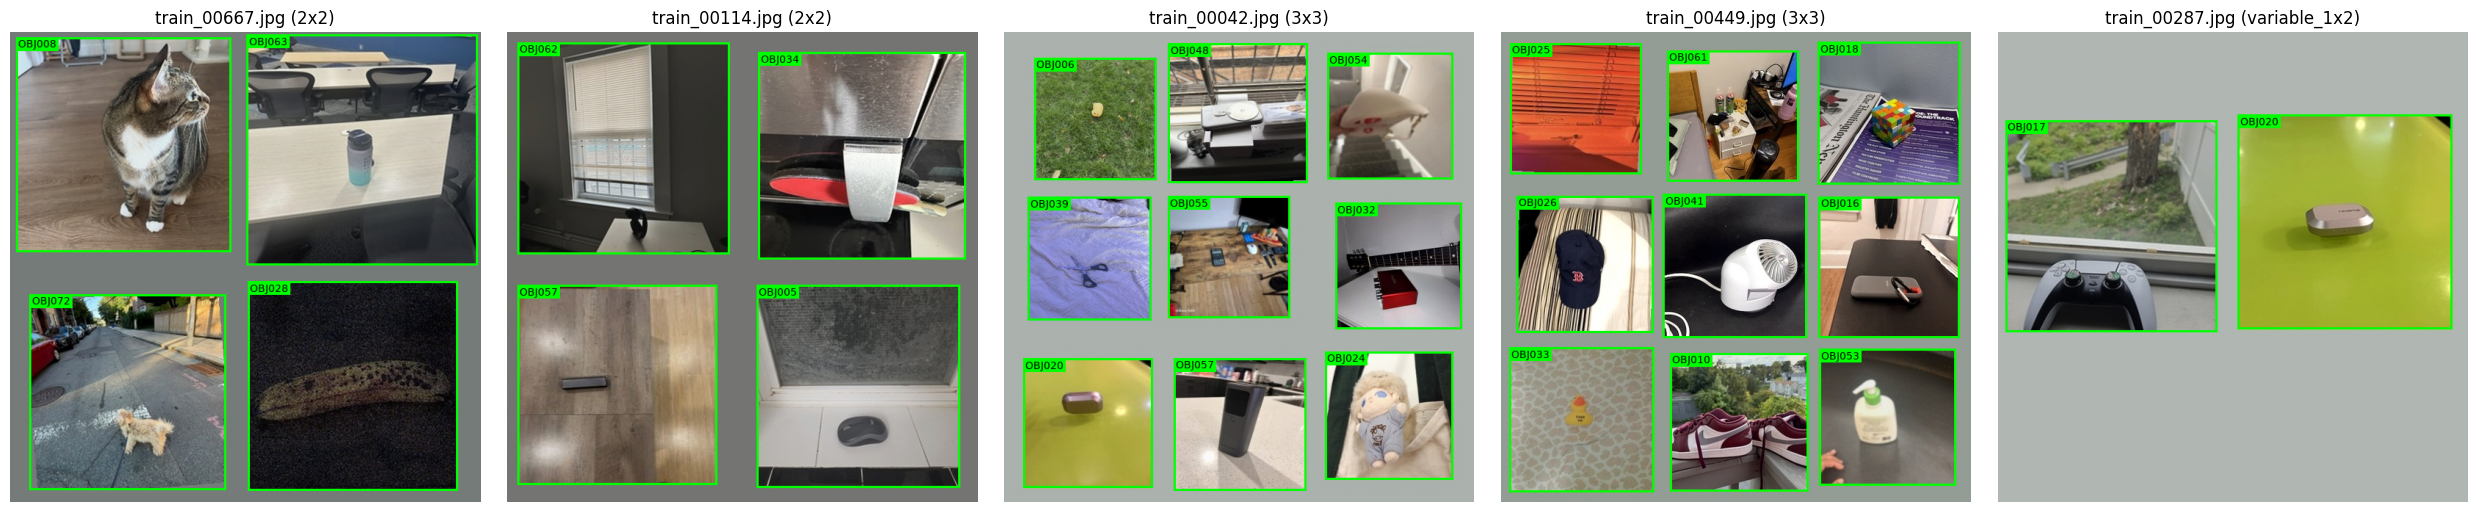

In [15]:
def get_font(size=14):
    try:
        from matplotlib import font_manager
        return ImageFont.truetype(font_manager.findfont("DejaVu Sans"), size)
    except Exception:
        return ImageFont.load_default()


def draw_boxes(image, boxes, labels, color):
    image = image.copy()
    draw = ImageDraw.Draw(image)
    font = get_font(14)
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
        text_width = draw.textlength(label, font=font)
        draw.rectangle([x1, y1, x1 + text_width + 6, y1 + 18], fill=color)
        draw.text((x1 + 3, y1 + 1), label, fill="black" if color == "lime" else "white", font=font)
    return image


def read_yolo_label(composite_file):
    label_path = YOLO_DATASET_DIR / composite_file.replace("images/", "labels/", 1).replace(".jpg", ".txt")
    boxes, ids = [], []
    for line in label_path.read_text().splitlines():
        class_index, xc, yc, w, h = line.split()
        xc, yc, w, h = (float(v) * CANVAS_SIZE for v in (xc, yc, w, h))
        boxes.append((xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2))
        ids.append(INDEX_TO_OBJ[int(class_index)])
    return boxes, ids


sanity_rng = random.Random(SEED)
train_images = composite_manifest[composite_manifest["split"] == "train"].drop_duplicates("composite_file")
sanity_files = (sanity_rng.sample(sorted(train_images.loc[train_images["layout"] == "2x2", "composite_file"]), 2)
                + sanity_rng.sample(sorted(train_images.loc[train_images["layout"] == "3x3", "composite_file"]), 2)
                + sanity_rng.sample(sorted(train_images.loc[train_images["layout_group"] == "variable", "composite_file"]), 1))

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, composite_file in zip(axes, sanity_files):
    boxes, ids = read_yolo_label(composite_file)
    with Image.open(YOLO_DATASET_DIR / composite_file) as img:
        ax.imshow(draw_boxes(img.convert("RGB"), boxes, ids, "lime"))
    layout = train_images.set_index("composite_file").loc[composite_file, "layout"]
    ax.set_title(f"{Path(composite_file).name} ({layout})")
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ground_truth_sanity_check.png", dpi=80)
plt.show()

## 11. YOLOv8 Training

Pretrained `yolov8s.pt` (COCO) fine-tuned on the 73-class composites. The dataset is copied to Colab's local SSD (`/content/yolo_dataset`) for speed; checkpoints and logs are written to `artifacts/runs/` on Drive. Model selection uses validation mAP (Ultralytics `best.pt`); the test split is not touched during training.

Rerun safety: a finished `best.pt` trained with the same dataset and training configuration is reused (set `FORCE_RETRAIN = True` to train again); an interrupted run with the same configuration is resumed from `last.pt`.

In [16]:
assert DATASET_READY, "dataset validation has not passed"
assert ULTRALYTICS_AVAILABLE, "ultralytics is not installed"
if not torch.cuda.is_available():
    raise RuntimeError("No GPU available. Select Runtime > Change runtime type > T4 GPU, then Runtime > Run all.")
print("GPU:", torch.cuda.get_device_name(0), "| CUDA", torch.version.cuda)
print("FINAL YOLO DATASET READINESS: PASS")

# Copying the dataset to the Colab local SSD for faster training
if IN_COLAB:
    if LOCAL_TRAIN_DATASET_DIR.exists():
        shutil.rmtree(LOCAL_TRAIN_DATASET_DIR)
    shutil.copytree(YOLO_DATASET_DIR, LOCAL_TRAIN_DATASET_DIR)
    TRAIN_DATA_YAML = write_data_yaml(LOCAL_TRAIN_DATASET_DIR, LOCAL_TRAIN_DATASET_DIR / "data.yaml")
else:
    TRAIN_DATA_YAML = DATA_YAML
print("Training data:", TRAIN_DATA_YAML)

training_args = {key: value for key, value in TRAIN_CONFIG.items() if key != "model"}
print("Training configuration:")
for key, value in TRAIN_CONFIG.items():
    print(f"  {key}: {value}")

# Deciding whether to train: reuse a finished run, resume an interrupted one, or start fresh
TRAIN_RUN_DIR = RUNS_DIR / TRAIN_RUN_NAME
LAST_WEIGHTS = TRAIN_RUN_DIR / "weights" / "last.pt"
RUN_CONFIG_FILE = TRAIN_RUN_DIR / "training_config.json"
current_run_config = json.loads(json.dumps({"dataset": DATASET_CONFIG, "train": TRAIN_CONFIG}))


def checkpoint_finished(path):
    # Ultralytics removes the optimizer state from checkpoints when training ends
    if not path.exists():
        return False
    try:
        return torch.load(path, map_location="cpu", weights_only=False).get("optimizer") is None
    except Exception:
        return False


same_config = RUN_CONFIG_FILE.exists() and json.loads(RUN_CONFIG_FILE.read_text()) == current_run_config
if not FORCE_RETRAIN and same_config and checkpoint_finished(BEST_WEIGHTS):
    TRAINING_MODE = "reuse"
elif not FORCE_RETRAIN and same_config and LAST_WEIGHTS.exists() and not checkpoint_finished(LAST_WEIGHTS):
    TRAINING_MODE = "resume"
else:
    TRAINING_MODE = "fresh"
print("\nTraining mode:", TRAINING_MODE)

GPU: Tesla T4 | CUDA 13.0
FINAL YOLO DATASET READINESS: PASS
Training data: /content/yolo_dataset/data.yaml
Training configuration:
  model: yolov8s.pt
  imgsz: 640
  epochs: 50
  batch: 16
  device: 0
  patience: 10
  seed: 42
  pretrained: True
  workers: 2
  cache: True
  save: True
  deterministic: True
  mosaic: 0.0
  close_mosaic: 0
  mixup: 0.0
  copy_paste: 0.0
  degrees: 0.0
  translate: 0.05
  scale: 0.2
  fliplr: 0.5
  hsv_h: 0.01
  hsv_s: 0.4
  hsv_v: 0.3

Training mode: fresh


In [17]:
# Smoke test: 1 epoch on 10% of train to confirm data loading, CUDA, losses and checkpointing
if RUN_SMOKE_TEST and TRAINING_MODE == "fresh":
    smoke_model = YOLO(TRAIN_CONFIG["model"])
    smoke_model.train(data=str(TRAIN_DATA_YAML), **{**training_args, "epochs": 1, "fraction": 0.1, "cache": False, "plots": False},
                      project="/content/smoke_run", name="smoke", exist_ok=True)
    smoke_dir = Path(smoke_model.trainer.save_dir)
    smoke_log = pd.read_csv(smoke_dir / "results.csv")
    smoke_log.columns = smoke_log.columns.str.strip()
    loss_columns = [c for c in smoke_log.columns if "loss" in c]
    display(smoke_log[loss_columns])
    assert loss_columns and np.isfinite(smoke_log[loss_columns].values).all(), "losses missing or not finite"
    assert (smoke_dir / "weights" / "last.pt").exists(), "checkpoint was not saved"
    print("SMOKE TEST: PASS")
    shutil.rmtree("/content/smoke_run", ignore_errors=True)
    del smoke_model

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=smoke, nbs=64, nms=None, opset=None, optimize=False, optimize

,train/box_loss,train/cls_loss,train/dfl_loss,val/box_loss,val/cls_loss,val/dfl_loss
0,1.12947,5.74801,1.42631,0.75734,6.03849,1.21093


SMOKE TEST: PASS


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8s_milestone2, nbs=64, nms=None, opset=None, optimize=Fa

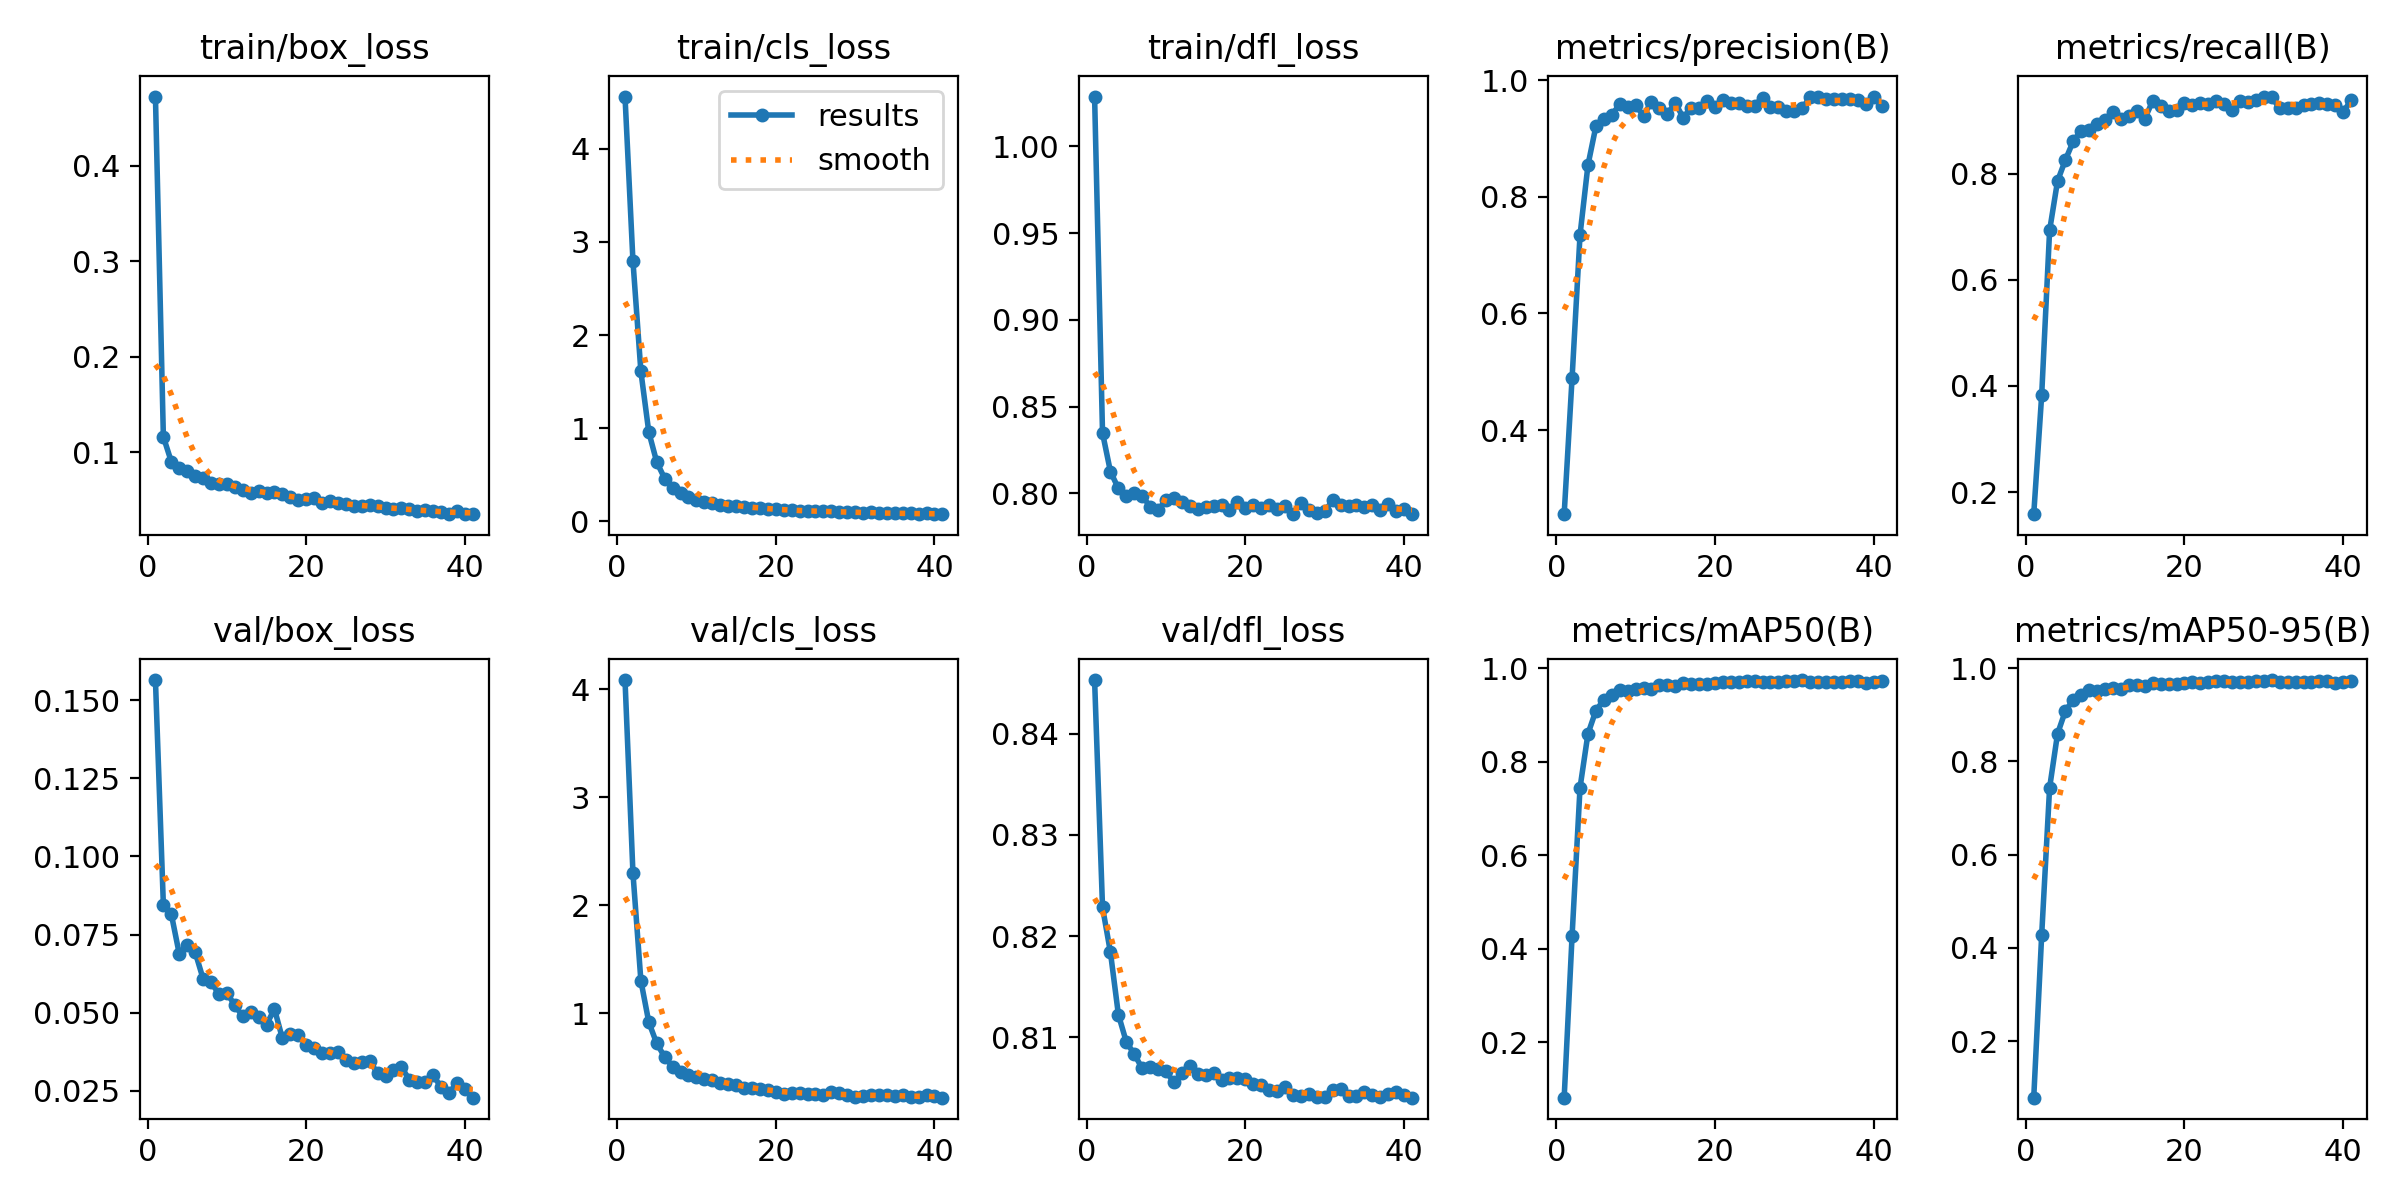

In [18]:
# Full fine-tuning run
if TRAINING_MODE == "reuse":
    print("Finished best.pt for this configuration found - skipping training (FORCE_RETRAIN = False):", BEST_WEIGHTS)
elif TRAINING_MODE == "resume":
    print("Resuming interrupted run from", LAST_WEIGHTS)
    model = YOLO(str(LAST_WEIGHTS))
    model.train(resume=True)
else:
    if TRAIN_RUN_DIR.exists():
        shutil.rmtree(TRAIN_RUN_DIR)
    TRAIN_RUN_DIR.mkdir(parents=True)
    RUN_CONFIG_FILE.write_text(json.dumps(current_run_config, indent=2))
    model = YOLO(TRAIN_CONFIG["model"])
    model.train(data=str(TRAIN_DATA_YAML), project=str(RUNS_DIR), name=TRAIN_RUN_NAME, exist_ok=True, **training_args)

assert checkpoint_finished(BEST_WEIGHTS), f"no finished best.pt at {BEST_WEIGHTS}"
shutil.copy(BEST_WEIGHTS, MODELS_DIR / "milestone2_yolov8s_best.pt")

training_log = pd.read_csv(TRAIN_RUN_DIR / "results.csv")
training_log.columns = training_log.columns.str.strip()
best_epoch_row = training_log.loc[training_log["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs run: {len(training_log)} | best validation epoch: {int(best_epoch_row['epoch'])} | "
      f"val mAP50={best_epoch_row['metrics/mAP50(B)']:.3f} mAP50-95={best_epoch_row['metrics/mAP50-95(B)']:.3f}")
if (TRAIN_RUN_DIR / "results.png").exists():
    display(Image.open(TRAIN_RUN_DIR / "results.png"))

## 12. Overall Evaluation

`best.pt` on the held-out test composites (built only from test source photos).

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 193.7±250.0 MB/s, size: 107.4 KB)
val: Scanning /content/yolo_dataset/labels/test... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 528.2it/s 0.4s
val: New cache created: /content/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.1it/s 6.1s
                   all        200       1081      0.973      0.923      0.967      0.967
                OBJ001         15         15      0.981          1      0.995      0.995
                OBJ002         15         15      0.996          1      0.995      0.995
                OBJ003         15         15       0.94      0.933      0.991      0.991
                OBJ004         14         14      0.997          1      0

,images,objects,precision,recall,mAP50,mAP50-95
0,200,1081,0.973,0.9225,0.9666,0.9666


confusion_matrix_normalized.png


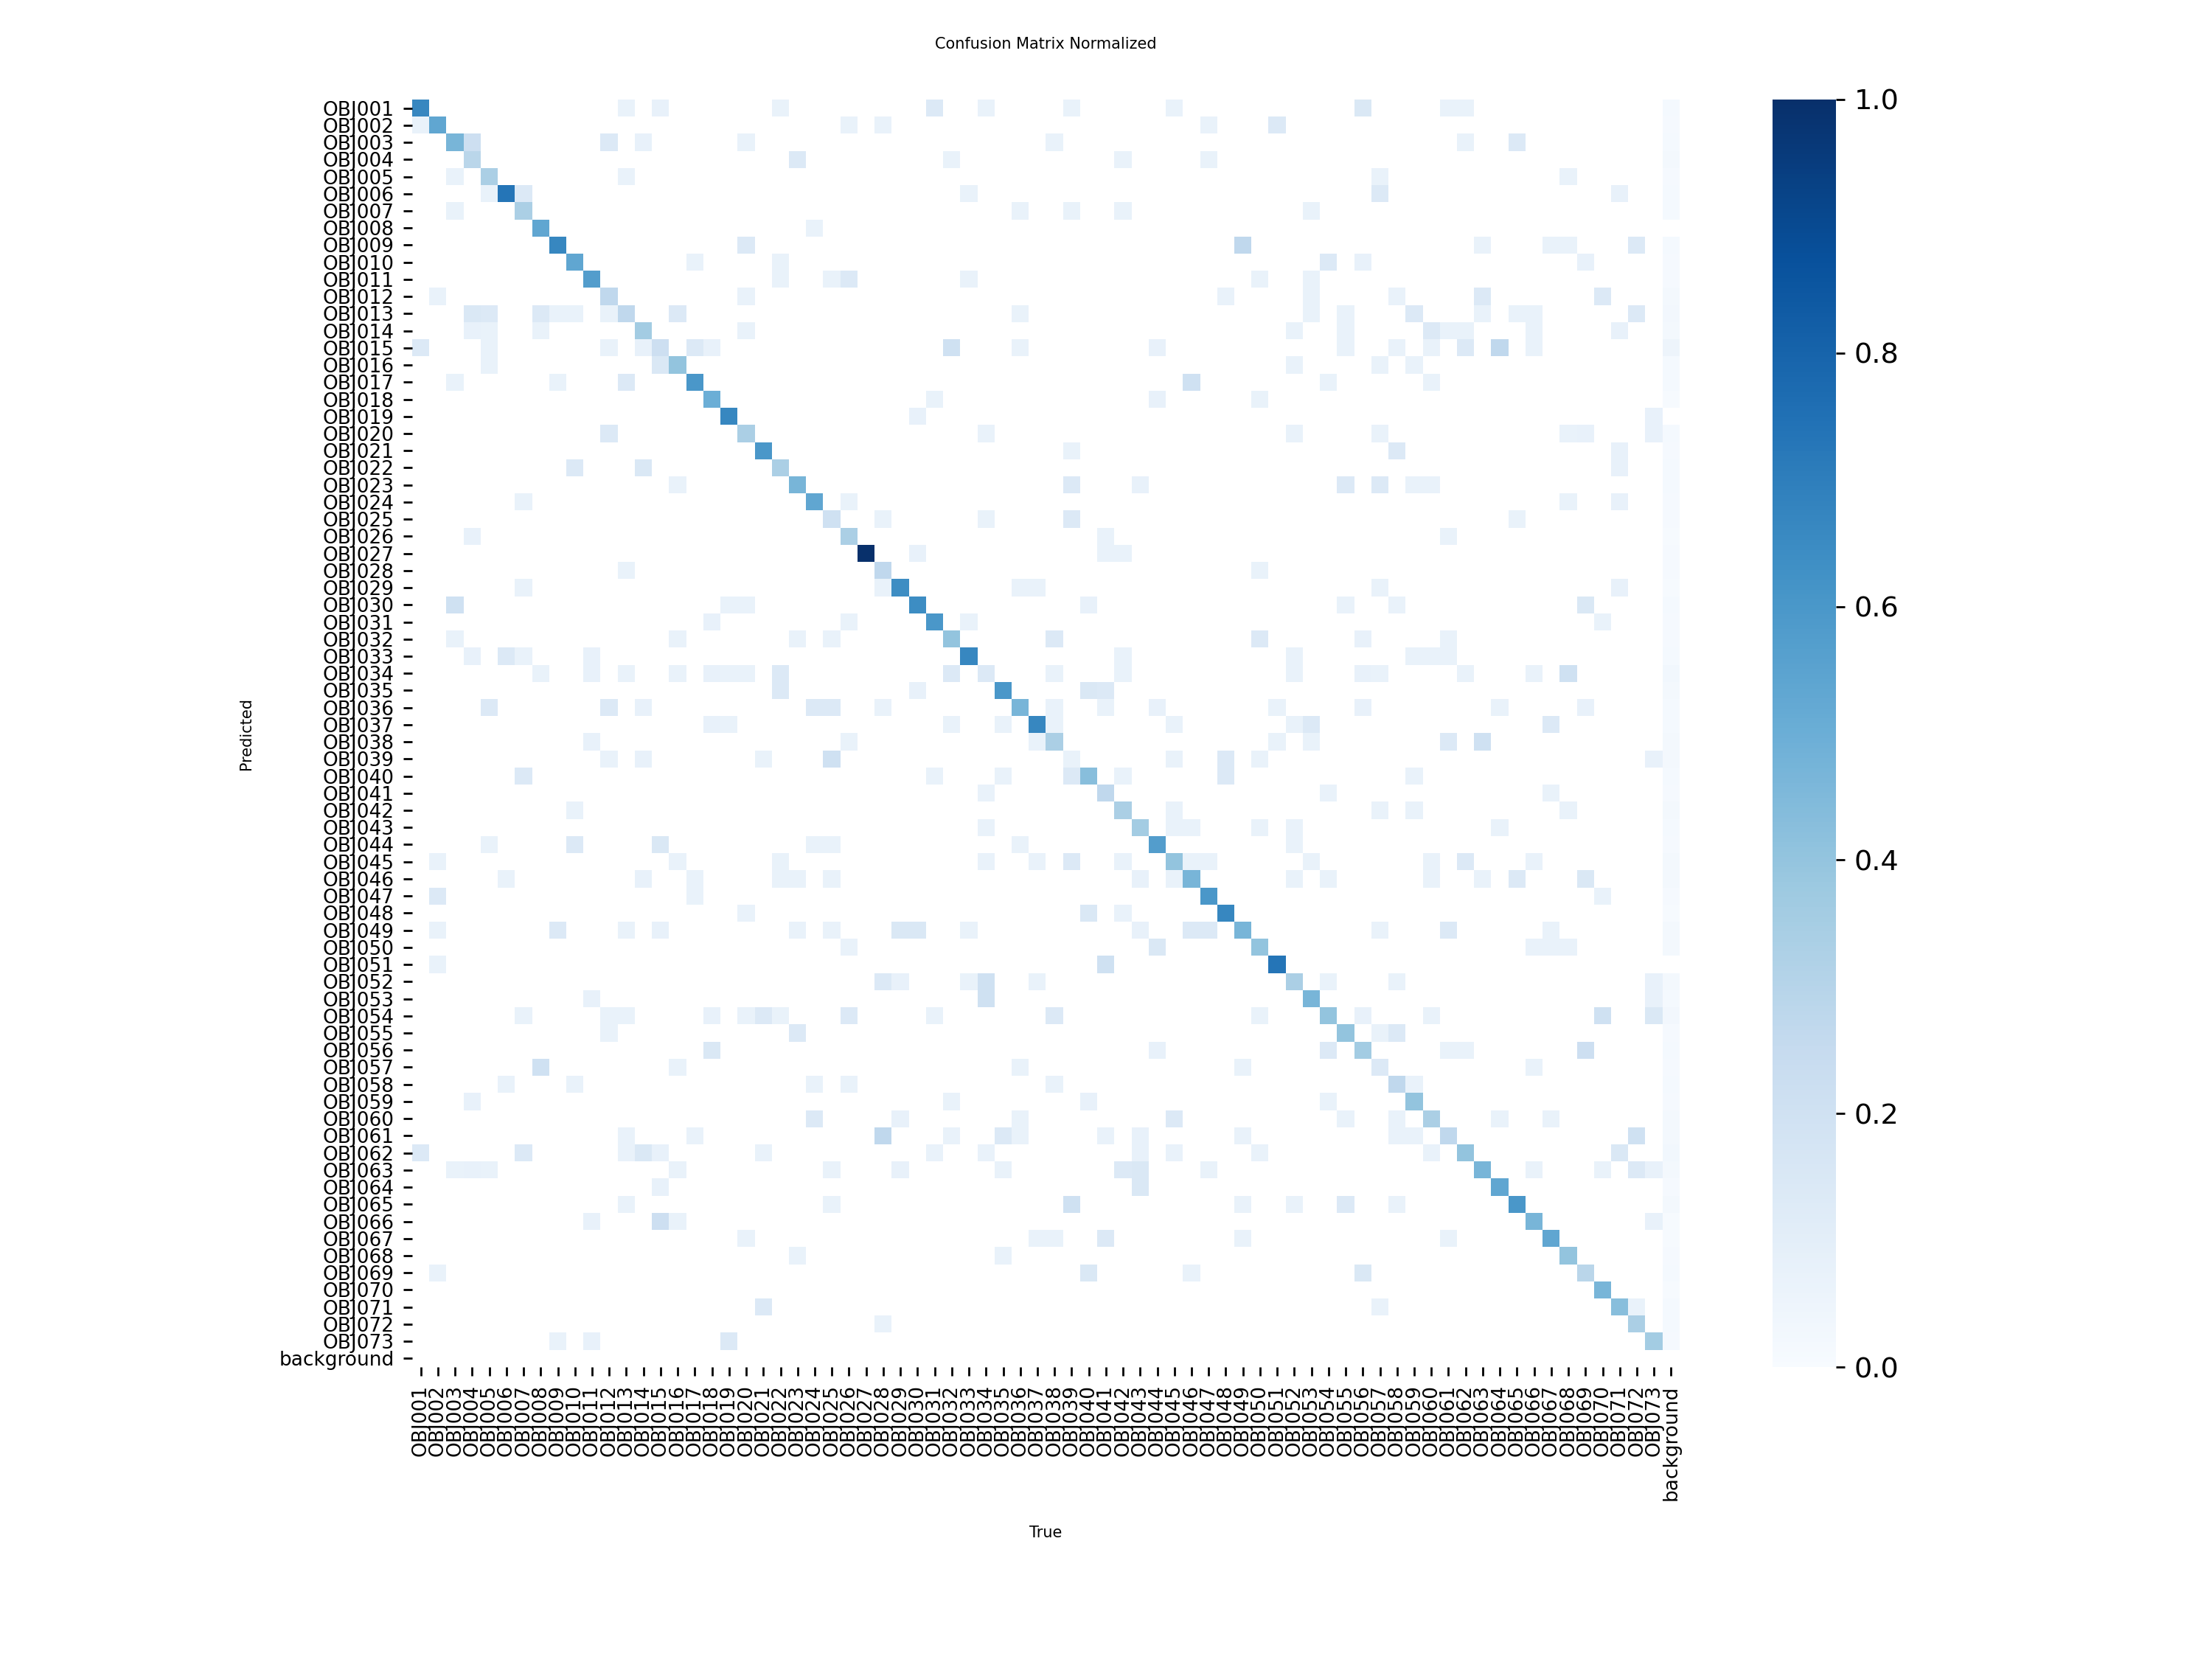

BoxPR_curve.png


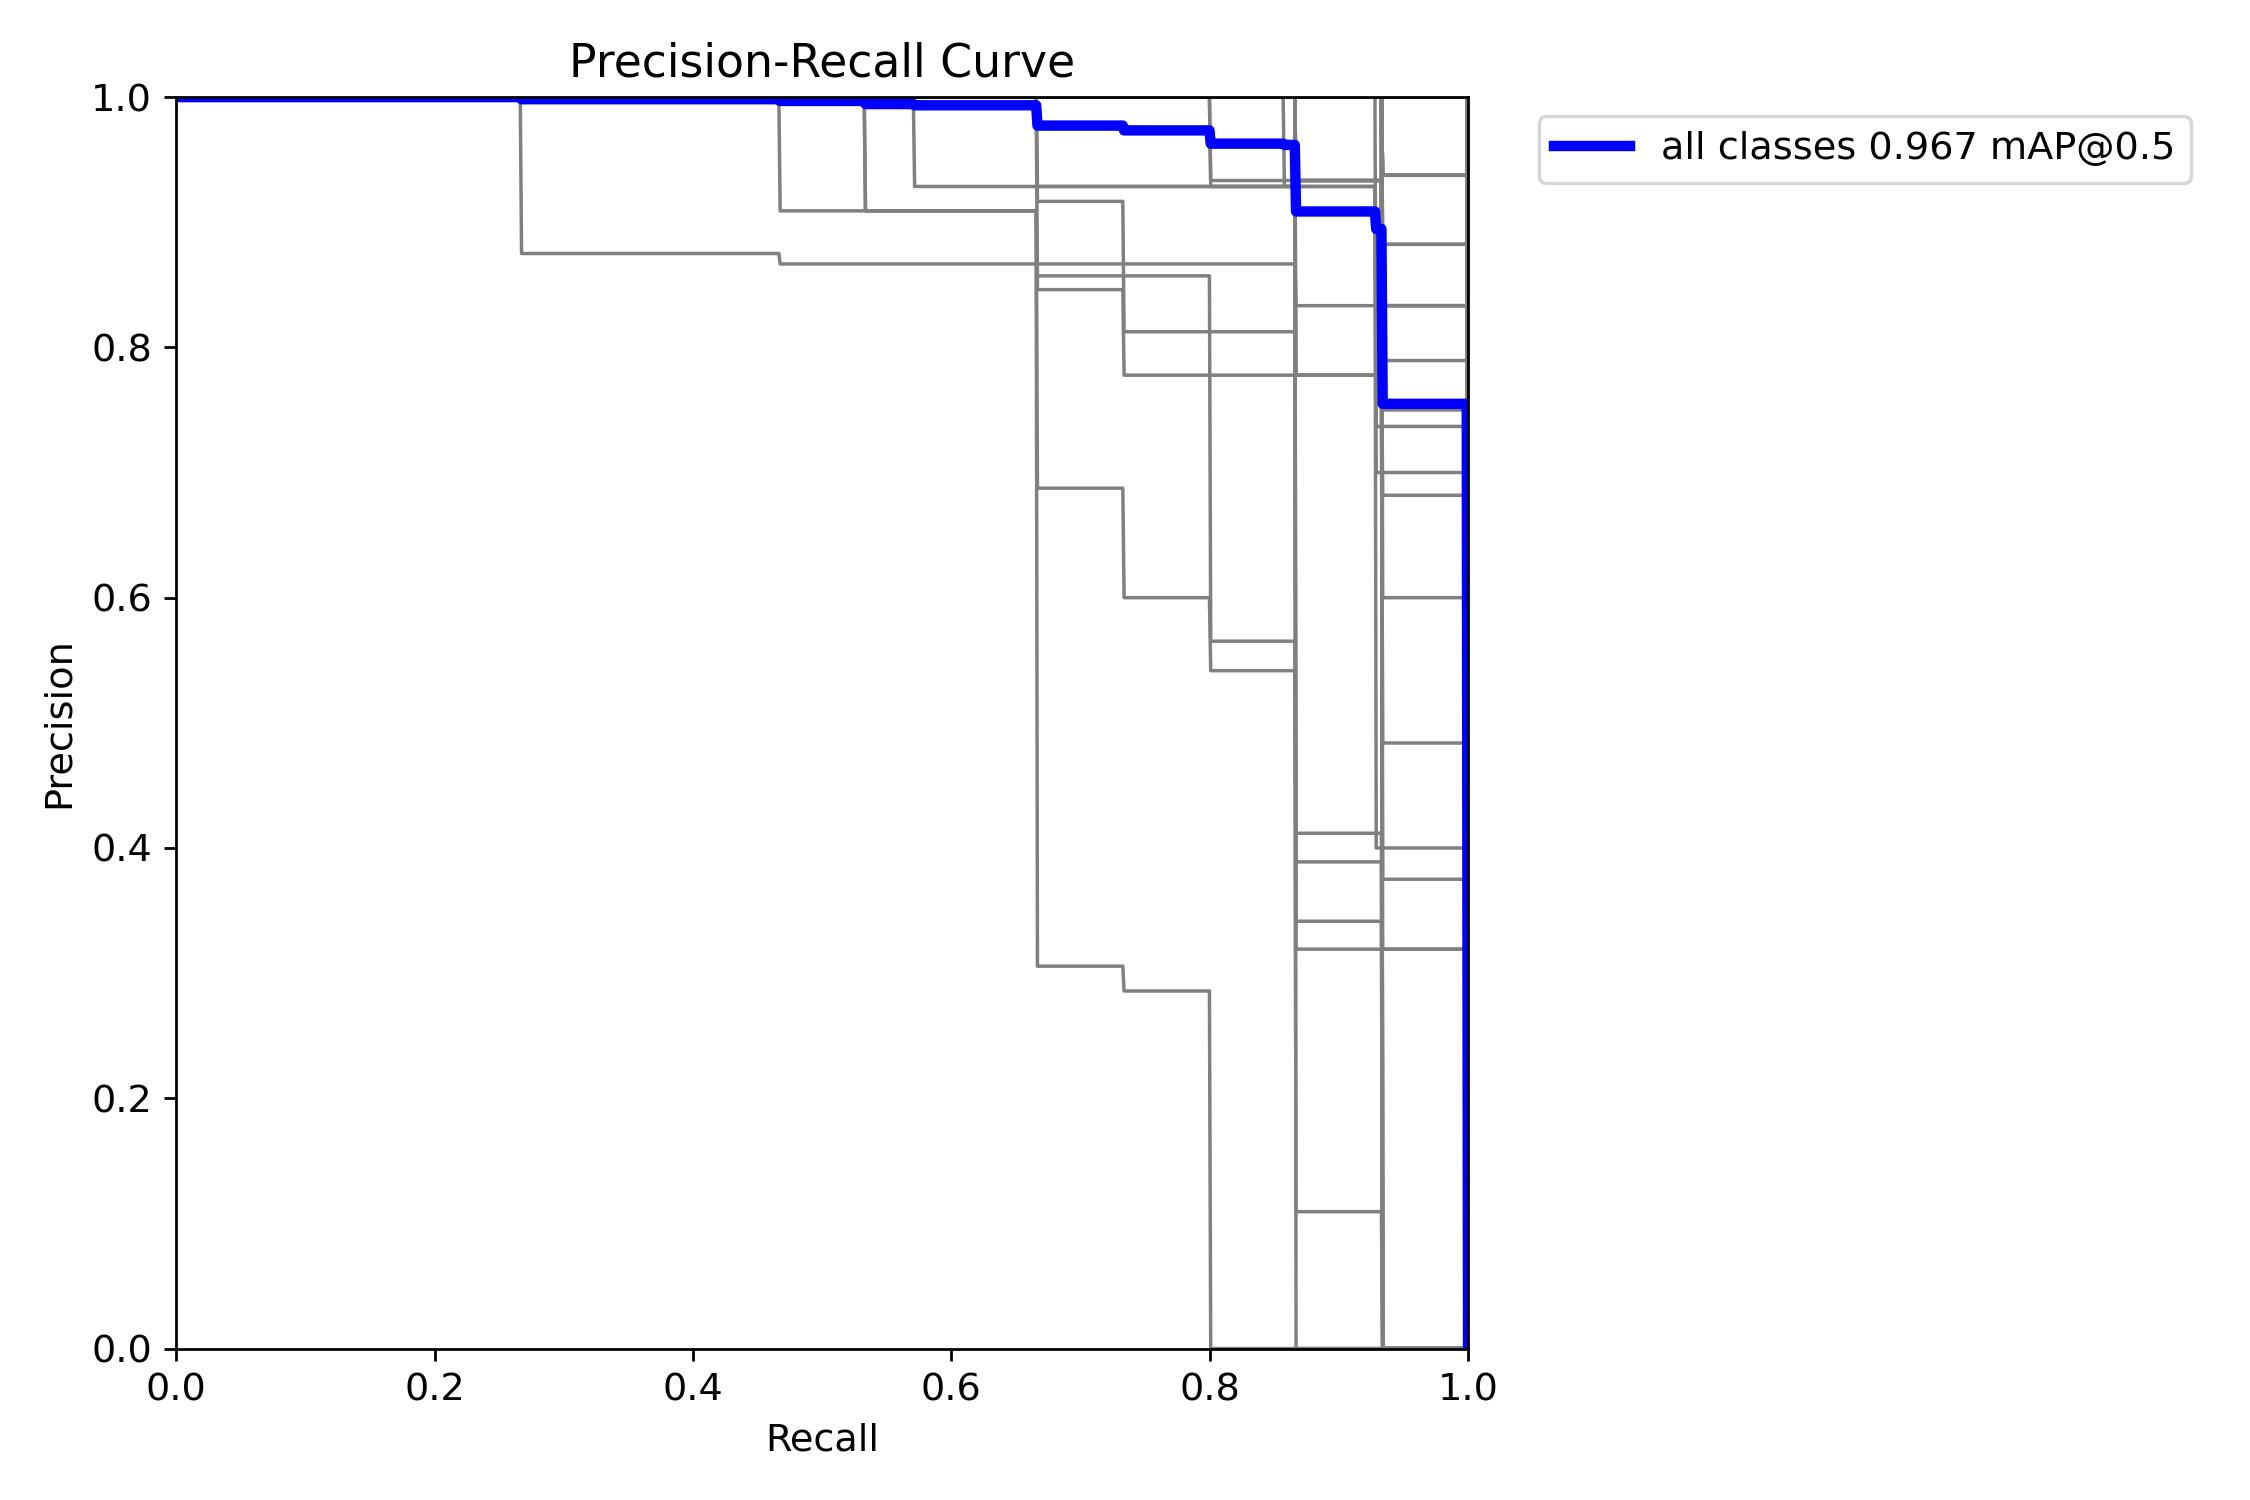

In [19]:
# Evaluating the detector on the held-out test set
best_model = YOLO(str(BEST_WEIGHTS))
assert [best_model.names[i] for i in range(NUM_CLASSES)] == OFFICIAL_IDS, "model class names do not match OBJ001..OBJ073"

test_metrics = best_model.val(data=str(TRAIN_DATA_YAML), split="test", imgsz=TRAIN_CONFIG["imgsz"], batch=16,
                              device=DEVICE, plots=True, project=str(RUNS_DIR), name="test_evaluation", exist_ok=True)
overall_results = {
    "images": TEST_COMPOSITES,
    "objects": int((composite_manifest["split"] == "test").sum()),
    "precision": test_metrics.box.mp,
    "recall": test_metrics.box.mr,
    "mAP50": test_metrics.box.map50,
    "mAP50-95": test_metrics.box.map,
}
overall_df = pd.DataFrame([overall_results])
overall_df.to_csv(RESULTS_DIR / "overall_test_metrics.csv", index=False)
display(overall_df.round(4))

per_class_ap = pd.DataFrame({
    "class_index": test_metrics.box.ap_class_index,
    "object_id": [INDEX_TO_OBJ[int(i)] for i in test_metrics.box.ap_class_index],
    "object_name": [OBJ_TO_NAME[INDEX_TO_OBJ[int(i)]] for i in test_metrics.box.ap_class_index],
    "precision": test_metrics.box.p,
    "recall": test_metrics.box.r,
    "AP50": test_metrics.box.ap50,
    "AP50-95": test_metrics.box.ap,
})
per_class_ap.to_csv(RESULTS_DIR / "per_class_ap.csv", index=False)

TEST_EVAL_DIR = Path(test_metrics.save_dir)
for pattern in ["confusion_matrix_normalized.png", "*PR_curve.png"]:
    for plot_file in sorted(TEST_EVAL_DIR.glob(pattern)):
        shutil.copy(plot_file, RESULTS_DIR / plot_file.name)
        print(plot_file.name)
        display(Image.open(plot_file))

## 13. 2x2 / 3x3 Evaluation

The test set is split into three subsets by layout group and each is evaluated separately with the same `best.pt`.

In [20]:
layout_rows = []
test_images = composite_manifest[composite_manifest["split"] == "test"].drop_duplicates("composite_file")
layout_eval_root = Path("/content/layout_eval") if IN_COLAB else ARTIFACTS_ROOT / "layout_eval"

for group in ["2x2", "3x3", "variable"]:
    group_files = test_images.loc[test_images["layout_group"] == group, "composite_file"].tolist()
    subset_dir = layout_eval_root / group
    if subset_dir.exists():
        shutil.rmtree(subset_dir)
    (subset_dir / "images" / "test").mkdir(parents=True)
    (subset_dir / "labels" / "test").mkdir(parents=True)
    for composite_file in group_files:
        label_file = composite_file.replace("images/", "labels/", 1).replace(".jpg", ".txt")
        shutil.copy(YOLO_DATASET_DIR / composite_file, subset_dir / "images" / "test")
        shutil.copy(YOLO_DATASET_DIR / label_file, subset_dir / "labels" / "test")
    subset_yaml = write_data_yaml(subset_dir, subset_dir / "data.yaml", train="images/test", val="images/test", test="images/test")

    group_metrics = best_model.val(data=str(subset_yaml), split="test", imgsz=TRAIN_CONFIG["imgsz"], batch=16, device=DEVICE,
                                   plots=False, project=str(RUNS_DIR), name=f"test_{group}", exist_ok=True, verbose=False)
    layout_rows.append({"layout": group, "images": len(group_files),
                        "objects": int(composite_manifest.loc[composite_manifest["composite_file"].isin(group_files)].shape[0]),
                        "precision": group_metrics.box.mp, "recall": group_metrics.box.mr,
                        "mAP50": group_metrics.box.map50, "mAP50-95": group_metrics.box.map})

layout_df = pd.DataFrame(layout_rows)
layout_df.to_csv(RESULTS_DIR / "layout_test_metrics.csv", index=False)
display(layout_df.round(4))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2222.9±720.2 MB/s, size: 124.6 KB)
val: Scanning /content/layout_eval/2x2/labels/test... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 2.1Kit/s 0.0s
val: New cache created: /content/layout_eval/2x2/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.7it/s 1.9s
                   all        100        400      0.967       0.93      0.974      0.974
Speed: 1.0ms preprocess, 11.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2582.3±798.2 MB/s, size: 134.6 KB)
va

,layout,images,objects,precision,recall,mAP50,mAP50-95
0,2x2,100,400,0.9675,0.9305,0.9738,0.9738
1,3x3,60,540,0.9696,0.9135,0.9624,0.9624
2,variable,40,141,0.9486,0.9141,0.9527,0.9527


## 14. Demo Inference

One unseen 2x2 and one unseen 3x3 test composite. Predicted class indices are converted back to official OBJ IDs; locations are pixel coordinates in the 640×640 image. Detections are matched to ground truth at IoU ≥ 0.5.

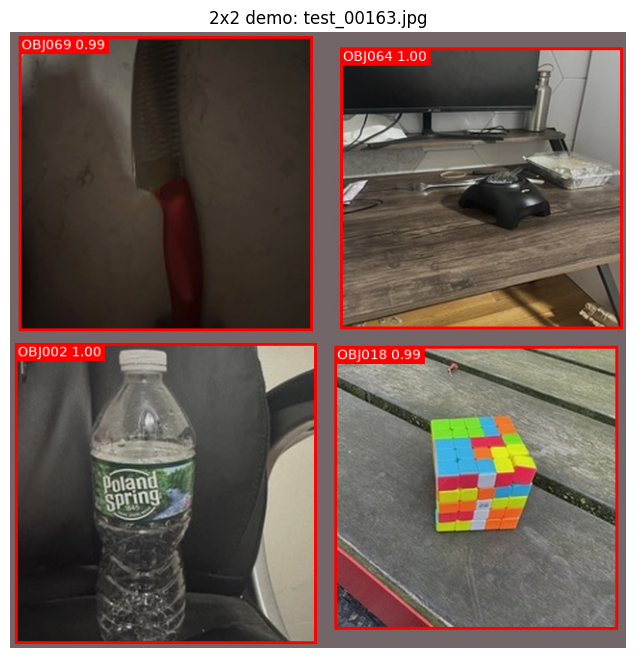

,image,object_id,confidence,x1,y1,x2,y2
0,test_00163.jpg,OBJ002,0.998,5,323,318,635
1,test_00163.jpg,OBJ064,0.996,343,16,636,308
2,test_00163.jpg,OBJ069,0.995,9,4,314,310
3,test_00163.jpg,OBJ018,0.992,337,326,631,620


  image        : test_00163.jpg
  true_ids     : ['OBJ002', 'OBJ018', 'OBJ064', 'OBJ069']
  detected_ids : ['OBJ002', 'OBJ018', 'OBJ064', 'OBJ069']
  missed       : []
  incorrect    : []


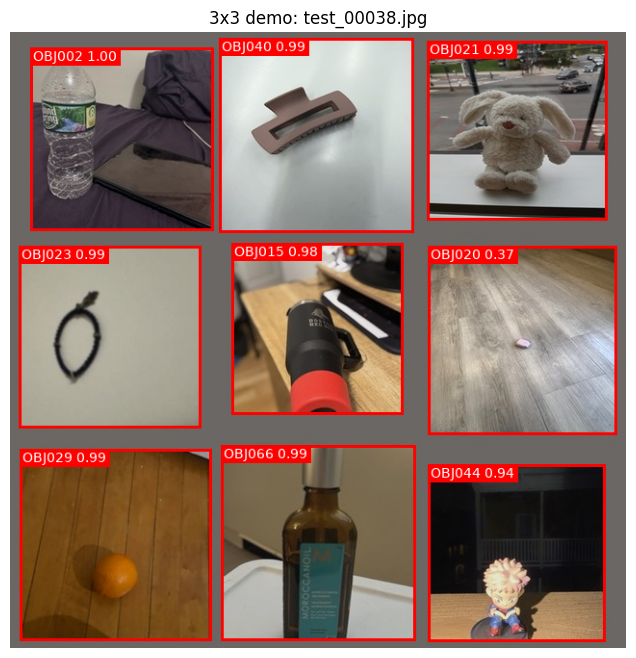

,image,object_id,confidence,x1,y1,x2,y2
0,test_00038.jpg,OBJ002,0.997,21,16,211,206
1,test_00038.jpg,OBJ029,0.994,10,433,209,632
2,test_00038.jpg,OBJ040,0.992,217,6,419,208
3,test_00038.jpg,OBJ021,0.992,433,9,620,195
4,test_00038.jpg,OBJ023,0.990,9,222,198,411
5,test_00038.jpg,OBJ066,0.988,219,429,421,632
6,test_00038.jpg,OBJ015,0.984,230,219,408,397
7,test_00038.jpg,OBJ044,0.944,434,449,618,633
8,test_00038.jpg,OBJ020,0.371,434,222,630,418


  image        : test_00038.jpg
  true_ids     : ['OBJ002', 'OBJ015', 'OBJ020', 'OBJ021', 'OBJ023', 'OBJ029', 'OBJ040', 'OBJ044', 'OBJ066']
  detected_ids : ['OBJ002', 'OBJ015', 'OBJ020', 'OBJ021', 'OBJ023', 'OBJ029', 'OBJ040', 'OBJ044', 'OBJ066']
  missed       : []
  incorrect    : []


In [21]:
def predict_objects(image_path):
    result = best_model.predict(str(image_path), conf=CONF_THRESHOLD, imgsz=TRAIN_CONFIG["imgsz"], device=DEVICE, verbose=False)[0]
    detections = []
    for (x1, y1, x2, y2), class_index, confidence in zip(result.boxes.xyxy.cpu().numpy(),
                                                         result.boxes.cls.cpu().numpy().astype(int),
                                                         result.boxes.conf.cpu().numpy()):
        detections.append({"object_id": INDEX_TO_OBJ[int(class_index)], "confidence": round(float(confidence), 3),
                           "x1": int(round(x1)), "y1": int(round(y1)), "x2": int(round(x2)), "y2": int(round(y2))})
    return detections


def box_iou(a, b):
    inter_w = max(0, min(a["x2"], b["x2"]) - max(a["x1"], b["x1"]))
    inter_h = max(0, min(a["y2"], b["y2"]) - max(a["y1"], b["y1"]))
    inter = inter_w * inter_h
    union = (a["x2"] - a["x1"]) * (a["y2"] - a["y1"]) + (b["x2"] - b["x1"]) * (b["y2"] - b["y1"]) - inter
    return inter / union if union > 0 else 0.0


def compare_with_ground_truth(ground_truth, detections):
    # Pass 1: match detections of the correct class (highest confidence first).
    # Pass 2: remaining detections become wrong_class, duplicate or false_positive.
    # Ground-truth objects nobody matched are missed.
    detections = sorted(detections, key=lambda d: -d["confidence"])
    gt_status = [None] * len(ground_truth)
    used = [False] * len(detections)
    outcomes = []
    for d_index, det in enumerate(detections):
        best_gt, best_iou = None, IOU_MATCH_THRESHOLD
        for g_index, gt in enumerate(ground_truth):
            if gt_status[g_index] is None and gt["object_id"] == det["object_id"] and box_iou(gt, det) >= best_iou:
                best_gt, best_iou = g_index, box_iou(gt, det)
        if best_gt is not None:
            gt_status[best_gt] = "correct"
            used[d_index] = True
            outcomes.append({"status": "correct", "true_object_id": ground_truth[best_gt]["object_id"],
                             "pred_object_id": det["object_id"], "confidence": det["confidence"], "iou": round(best_iou, 3),
                             "box_width": ground_truth[best_gt]["x2"] - ground_truth[best_gt]["x1"]})
    for d_index, det in enumerate(detections):
        if used[d_index]:
            continue
        ious = [box_iou(gt, det) for gt in ground_truth]
        g_index = int(np.argmax(ious))
        if ious[g_index] < IOU_MATCH_THRESHOLD:
            status, true_id = "false_positive", ""
        elif gt_status[g_index] is None:
            gt_status[g_index] = "wrong_class"
            status, true_id = "wrong_class", ground_truth[g_index]["object_id"]
        else:
            status, true_id = "duplicate", ground_truth[g_index]["object_id"]
        outcomes.append({"status": status, "true_object_id": true_id, "pred_object_id": det["object_id"],
                         "confidence": det["confidence"], "iou": round(ious[g_index], 3),
                         "box_width": ground_truth[g_index]["x2"] - ground_truth[g_index]["x1"] if true_id else np.nan})
    for g_index, gt in enumerate(ground_truth):
        if gt_status[g_index] is None:
            outcomes.append({"status": "missed", "true_object_id": gt["object_id"], "pred_object_id": "",
                             "confidence": np.nan, "iou": np.nan, "box_width": gt["x2"] - gt["x1"]})
    return outcomes


demo_rng = random.Random(SEED)
demo_files = {
    "2x2": demo_rng.choice(sorted(test_images.loc[test_images["layout"] == "2x2", "composite_file"])),
    "3x3": demo_rng.choice(sorted(test_images.loc[test_images["layout"] == "3x3", "composite_file"])),
}
demo_tables, demo_summaries = {}, {}

for layout, composite_file in demo_files.items():
    image_name = Path(composite_file).name
    detections = predict_objects(YOLO_DATASET_DIR / composite_file)
    ground_truth = composite_manifest.loc[composite_manifest["composite_file"] == composite_file,
                                          ["object_id", "x1", "y1", "x2", "y2"]].to_dict("records")
    outcomes = pd.DataFrame(compare_with_ground_truth(ground_truth, detections))

    with Image.open(YOLO_DATASET_DIR / composite_file) as img:
        img = img.convert("RGB")
        img.save(DEMO_DIR / f"demo_{layout}_input.jpg", quality=95)
        annotated = draw_boxes(img, [(d["x1"], d["y1"], d["x2"], d["y2"]) for d in detections],
                               [f"{d['object_id']} {d['confidence']:.2f}" for d in detections], "red")
    annotated.save(DEMO_DIR / f"demo_{layout}_detections.jpg", quality=95)

    table = pd.DataFrame(detections, columns=["object_id", "confidence", "x1", "y1", "x2", "y2"])
    table.insert(0, "image", image_name)
    table.to_csv(DEMO_DIR / f"demo_{layout}_detections.csv", index=False)
    demo_tables[layout] = table

    true_ids = sorted(g["object_id"] for g in ground_truth)
    detected_ids = sorted(d["object_id"] for d in detections)
    demo_summaries[layout] = {
        "image": image_name,
        "true_ids": true_ids,
        "detected_ids": detected_ids,
        "missed": sorted(outcomes.loc[outcomes["status"] == "missed", "true_object_id"]),
        "incorrect": [f"{r.pred_object_id} (true {r.true_object_id or 'none'}, {r.status})"
                      for r in outcomes[outcomes["status"].isin(["wrong_class", "false_positive", "duplicate"])].itertuples()],
    }

    plt.figure(figsize=(8, 8))
    plt.imshow(annotated)
    plt.title(f"{layout} demo: {image_name}")
    plt.axis("off")
    plt.show()
    display(table)
    for key, value in demo_summaries[layout].items():
        print(f"  {key:13s}: {value}")

## 15. Error Analysis

All 200 test composites, detections at confidence ≥ 0.25 matched to ground truth at IoU ≥ 0.5.

In [22]:
all_outcomes = []
for composite_file, group in composite_manifest[composite_manifest["split"] == "test"].groupby("composite_file"):
    ground_truth = group[["object_id", "x1", "y1", "x2", "y2"]].to_dict("records")
    for outcome in compare_with_ground_truth(ground_truth, predict_objects(YOLO_DATASET_DIR / composite_file)):
        all_outcomes.append({"composite_file": composite_file, "layout_group": group["layout_group"].iloc[0], **outcome})
outcomes_df = pd.DataFrame(all_outcomes)
outcomes_df.to_csv(RESULTS_DIR / "test_detection_outcomes.csv", index=False)

print("Outcome counts (ground-truth objects:", int((composite_manifest["split"] == "test").sum()), ")")
display(outcomes_df["status"].value_counts().to_frame("count"))

# Object-level accuracy per layout group: share of ground-truth objects detected with the right OBJ ID
gt_outcomes = outcomes_df[outcomes_df["status"].isin(["correct", "wrong_class", "missed"])]
layout_accuracy = (gt_outcomes.groupby("layout_group")["status"].value_counts().unstack(fill_value=0)
                   .reindex(columns=["correct", "wrong_class", "missed"], fill_value=0))
layout_accuracy["object_accuracy"] = (layout_accuracy["correct"] / layout_accuracy.sum(axis=1)).round(4)
print("Per layout group:")
display(layout_accuracy)

# Smaller tiles come from more crowded layouts
gt_outcomes = gt_outcomes.assign(tile_size=pd.cut(gt_outcomes["box_width"], bins=[0, 150, 200, 250, 400],
                                                  labels=["<150px", "150-200px", "200-250px", ">250px"]))
size_accuracy = gt_outcomes.groupby("tile_size", observed=True)["status"].agg(
    objects="size", object_accuracy=lambda s: round((s == "correct").mean(), 4))
print("Per tile size:")
display(size_accuracy)

ranked = per_class_ap.sort_values("AP50-95", ascending=False)
strongest_classes = ranked.head(5)[["object_id", "object_name", "AP50", "AP50-95"]]
weakest_classes = ranked.tail(5).iloc[::-1][["object_id", "object_name", "AP50", "AP50-95"]]
print("Strongest classes:"); display(strongest_classes)
print("Weakest / lowest-AP classes:"); display(weakest_classes)

wrong = outcomes_df[outcomes_df["status"] == "wrong_class"]
confusion_pairs = (wrong.groupby(["true_object_id", "pred_object_id"]).size().sort_values(ascending=False)
                   .rename("count").reset_index().head(10))
print("Most common confusions (true -> predicted):"); display(confusion_pairs)

missed_examples = outcomes_df[outcomes_df["status"] == "missed"].head(5)[["composite_file", "layout_group", "true_object_id"]]
wrong_examples = wrong.head(5)[["composite_file", "layout_group", "true_object_id", "pred_object_id", "confidence"]]
duplicate_count = int((outcomes_df["status"] == "duplicate").sum())
print("Missed examples:"); display(missed_examples)
print("Wrong-classification examples:"); display(wrong_examples)
print("Duplicate detections:", duplicate_count)

map_2x2 = float(layout_df.loc[layout_df["layout"] == "2x2", "mAP50-95"].iloc[0])
map_3x3 = float(layout_df.loc[layout_df["layout"] == "3x3", "mAP50-95"].iloc[0])
print(f"3x3 mAP50-95 = {map_3x3:.3f} vs 2x2 mAP50-95 = {map_2x2:.3f} -> 3x3 is "
      f"{'weaker' if map_3x3 < map_2x2 else 'not weaker'} (difference {map_3x3 - map_2x2:+.3f})")

Outcome counts (ground-truth objects: 1081 )


,count
status,
correct,1017
wrong_class,34
missed,30
duplicate,11


Per layout group:


status,correct,wrong_class,missed,object_accuracy
layout_group,,,,
2x2,379,12,9,0.9475
3x3,505,17,18,0.9352
variable,133,5,3,0.9433


Per tile size:


...

Missed examples:


,composite_file,layout_group,true_object_id
64,images/test/test_00014.jpg,3x3,OBJ068
113,images/test/test_00023.jpg,3x3,OBJ045
138,images/test/test_00028.jpg,3x3,OBJ057
152,images/test/test_00030.jpg,variable,OBJ057
179,images/test/test_00035.jpg,2x2,OBJ034


Wrong-classification examples:


,composite_file,layout_group,true_object_id,pred_object_id,confidence
36,images/test/test_00010.jpg,variable,OBJ057,OBJ005,0.970
42,images/test/test_00011.jpg,variable,OBJ020,OBJ012,0.367
55,images/test/test_00013.jpg,3x3,OBJ037,OBJ027,0.816
63,images/test/test_00014.jpg,3x3,OBJ013,OBJ003,0.904
100,images/test/test_00021.jpg,3x3,OBJ056,OBJ010,0.412


Duplicate detections: 11
3x3 mAP50-95 = 0.962 vs 2x2 mAP50-95 = 0.974 -> 3x3 is weaker (difference -0.011)


## 16. Final Results

Writes `milestone2_results_summary.md` to the project folder using only the measured values above.

In [23]:
def markdown_table(df):
    header = "| " + " | ".join(df.columns) + " |"
    divider = "|" + "|".join(["---"] * len(df.columns)) + "|"
    rows = ["| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, divider] + rows)


source_counts = source_split["split"].value_counts()
layout_counts = images_per_layout["layout_group"].value_counts()
total_objects = len(gt_outcomes)
status_counts = outcomes_df["status"].value_counts()

observations = [
    f"Test set: {int(status_counts.get('correct', 0))}/{total_objects} ground-truth objects detected with the correct OBJ ID "
    f"at conf >= {CONF_THRESHOLD}; {int(status_counts.get('wrong_class', 0))} wrong class, {int(status_counts.get('missed', 0))} missed, "
    f"{int(status_counts.get('false_positive', 0))} false positives, {duplicate_count} duplicates.",
    f"Layout: 3x3 mAP50-95 {map_3x3:.3f} vs 2x2 {map_2x2:.3f} ({map_3x3 - map_2x2:+.3f}).",
    "Object accuracy by tile width: " + ", ".join(f"{size} {row['object_accuracy']:.3f} (n={int(row['objects'])})" for size, row in size_accuracy.iterrows()) + ".",
    "Weakest classes (AP50-95): " + ", ".join(f"{row['object_id']} {row['AP50-95']:.3f}" for _, row in weakest_classes.iterrows()) + ".",
    "Most common confusions: " + (", ".join(f"{row['true_object_id']}->{row['pred_object_id']} ({row['count']})" for _, row in confusion_pairs.head(5).iterrows())
                                  if len(confusion_pairs) else "none") + ".",
]

sample_sections = []
for layout in ["2x2", "3x3"]:
    s = demo_summaries[layout]
    sample_sections.append(
        f"**{layout}** - `{s['image']}` -> `artifacts/demo_results/demo_{layout}_detections.jpg`\n\n"
        + markdown_table(demo_tables[layout]) + "\n\n"
        + f"True: {', '.join(s['true_ids'])}  \nMissed: {', '.join(s['missed']) or 'none'}  \nIncorrect: {', '.join(s['incorrect']) or 'none'}")

summary = f"""# Milestone 2 - Object Detection Results

## Dataset Generation
{len(sources)} usable single-object photos of the 73 official classes (OBJ001-OBJ073; {len(BACKGROUND_FILES)} background-only images excluded) were split per class 70/15/15 with seed {SEED} into train/val/test source pools ({source_counts['train']}/{source_counts['val']}/{source_counts['test']} photos) before any composite was built. Each split's composites use only that split's photos. {TRAIN_COMPOSITES}/{VAL_COMPOSITES}/{TEST_COMPOSITES} train/val/test 640x640 composites ({len(images_per_layout)} total; {layout_counts.get('2x2', 0)} 2x2, {layout_counts.get('3x3', 0)} 3x3, {layout_counts.get('variable', 0)} variable 1x2-3x3 grids with 2-6 objects) were generated by grid concatenation with balanced, unique classes per image and mild tile variation. Bounding boxes are the known pasted-tile rectangles, written automatically as YOLO labels ({len(composite_manifest)} object instances).

## Model
YOLOv8s (COCO-pretrained `yolov8s.pt`) fine-tuned for 73 classes: imgsz {TRAIN_CONFIG['imgsz']}, {len(training_log)} of max {TRAIN_CONFIG['epochs']} epochs (patience {TRAIN_CONFIG['patience']}), batch {TRAIN_CONFIG['batch']}, seed {SEED}, mosaic/mixup off, scale {TRAIN_CONFIG['scale']}, translate {TRAIN_CONFIG['translate']}, fliplr {TRAIN_CONFIG['fliplr']}. Best checkpoint selected on validation mAP50-95 (epoch {int(best_epoch_row['epoch'])}); GPU {environment_info.get('gpu')}, Ultralytics {environment_info.get('ultralytics')}.

## Overall Results
Held-out test set ({TEST_COMPOSITES} composites, {overall_results['objects']} objects):

{markdown_table(overall_df[['precision', 'recall', 'mAP50', 'mAP50-95']])}

## Layout Comparison
{markdown_table(layout_df)}

## Sample Detections
Pixel coordinates (x1, y1, x2, y2) in the 640x640 image, conf >= {CONF_THRESHOLD}.

{(chr(10) * 2).join(sample_sections)}

## Main Observations
{chr(10).join('- ' + line for line in observations)}
"""
(PROJECT_ROOT / "milestone2_results_summary.md").write_text(summary, encoding="utf-8")

run_info = {"environment": environment_info, "seed": SEED, "source_split_counts": source_counts.to_dict(),
            "composite_counts": COMPOSITE_COUNTS, "layout_counts": layout_counts.to_dict(),
            "train_config": TRAIN_CONFIG, "overall_test": overall_results}
(RESULTS_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print(summary)

# Milestone 2 - Object Detection Results

## Dataset Generation
6942 usable single-object photos of the 73 official classes (OBJ001-OBJ073; 373 background-only images excluded) were split per class 70/15/15 with seed 42 into train/val/test source pools (4832/1028/1082 photos) before any composite was built. Each split's composites use only that split's photos. 1000/200/200 train/val/test 640x640 composites (1400 total; 700 2x2, 420 3x3, 280 variable 1x2-3x3 grids with 2-6 objects) were generated by grid concatenation with balanced, unique classes per image and mild tile variation. Bounding boxes are the known pasted-tile rectangles, written automatically as YOLO labels (7573 object instances).

## Model
YOLOv8s (COCO-pretrained `yolov8s.pt`) fine-tuned for 73 classes: imgsz 640, 41 of max 50 epochs (patience 10), batch 16, seed 42, mosaic/mixup off, scale 0.2, translate 0.05, fliplr 0.5. Best checkpoint selected on validation mAP50-95 (epoch 31); GPU Tesla T4, Ultralytics 8.4.175.

## 